[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QuantumFL_BackdoorDefence_Raj2025.ipynb)

# Quantum-classical federated learning against backdoors in non-IID skin-lesion data: Raj et al. 2025, step by step

**Paper.** Naveen Raj R, Anusuya R, D. Karthika Renuka, Ashok Kumar L, *Quantum-Classical Federated Learning: Enhancing Robustness Against Backdoor Attacks in Non-IID Environments*, preprint on Authorea (not peer reviewed), 15 May 2025. DOI: [10.22541/au.174731423.33892933/v1](https://doi.org/10.22541/au.174731423.33892933/v1).

**What this notebook does.** It rebuilds the paper's pipeline on a CPU, with every step explained in plain language:

1. downloads a public copy of the ISIC skin-lesion images and turns them into 512 numbers per image with a *frozen* ImageNet ResNet-18 (the classical half of the hybrid model);
2. puts a small **variational quantum circuit** (PennyLane, 6 qubits) on top of those numbers: *features -> linear -> tanh x pi/2 -> circuit of RY / RX / RY / RZ gates and CNOTs -> Pauli-Z read-out -> linear -> softmax*;
3. trains it **federatedly** with the four aggregation rules of the paper (FedAvg, FedProx, FedNova, SCAFFOLD) over 10 simulated hospitals, with IID data and with Dirichlet non-IID data;
4. lets two hospitals be malicious and plant a **trigger backdoor** (a checkerboard patch) or a **semantic backdoor** (re-lit benign-looking lesions labelled as melanoma);
5. applies the four defences of the paper (Activation Clustering, Neural Cleanse, Fine-Pruning and the proposed **Spectral Defense**) and measures clean accuracy and the backdoor attack rate (BAR) before and after;
6. trains classical heads on exactly the same inputs, and compares every number with the paper's Tables 1 and 2, claim by claim.

**How to run.** In Colab choose a CPU runtime and press *Runtime -> Run all*. With `FAST_MODE = True` (default) it is a class demo with a small image subset and few rounds; with `FAST_MODE = False` it uses about 2,370 images, 20 rounds and 3 seeds (budgets are in the configuration cell; the full run takes roughly an hour on a laptop CPU). Only public data are used (no token needed); if you ever swap in a gated dataset, add your own `HF_TOKEN` under *Colab -> Secrets*.

**What you get at the end.** The dataset plots, the executed quantum circuit, federated learning curves, a table of attack rates, the paper's Tables 1 and 2 re-measured side by side with the paper's numbers, and an honest verdict per claim (reproduced / not reached / cannot be checked).

## The paper in one page

**Problem.** In federated learning (FL) several hospitals train one shared model without sending their images to a server. A compromised hospital can still hide a **backdoor** in the shared model: the model behaves normally on clean images, but an image carrying a secret *trigger* is sent to a class chosen by the attacker (for example "benign"). When the hospitals' data are **non-IID** (each hospital sees a different mix of diagnoses) honest updates differ a lot from each other, so a malicious update is harder to spot. The paper asks whether a *quantum-classical* model, plus a better aggregation rule and a new defence, makes this safer.

**Decision.** For each skin-lesion image: which diagnosis (9 classes in the paper's copy of the data)? For each trained federation: is there a backdoor, and can it be removed?

**Model (QCFL).** A ResNet-18 produces deep features. A learnable linear layer plus `tanh` scaled by pi/2 turns them into rotation angles `q_in = tanh(W f + b) * pi/2`. A **variational quantum circuit** (RY, RZ, RX rotations and CNOT entanglers, implemented in PennyLane inside a PyTorch module) acts on these angles, the Pauli-Z expectation values are read out and a linear layer with softmax gives the class (paper Section 4, Figs. 1-2). Its parameters are federated together with the classical ones.

**Aggregation.** FedAvg, FedProx, FedNova and SCAFFOLD (Section 4.3); non-IID shards are drawn from a Dirichlet distribution and their skew is measured by the Jensen-Shannon divergence (Section 5.3).

**Attacks.** *Trigger-based*: a malicious client stamps a fixed pattern on part of its images and relabels them to a target class. *Semantic-based*: natural-looking changes (brighter, less saturated, blurred benign lesions) labelled as melanoma (Section 5).

**Defences.** Activation Clustering, Neural Cleanse, Fine-Pruning, and the proposed **Spectral Defense**: per class, take the eigen-spectrum of the activations, score its entropy / variance / dominant eigenvalue with a robust (MAD) anomaly detector, scale or prune the neurons that fire above mu + 2 sigma in suspicious classes, then fine-tune with adversarial augmentation for five epochs (Section 6, Algorithm 1).

**Data.** 2,357 dermoscopic images from the International Skin Imaging Collaboration (ISIC), nine classes (actinic keratosis, basal cell carcinoma, dermatofibroma, melanoma, nevus, pigmented benign keratosis, seborrheic keratosis, squamous cell carcinoma, vascular lesion), a little more Melanoma and Nevus than the rest.

**Claims this notebook can test.**
1. The quantum-hybrid model beats the classical ResNet-18 on accuracy, precision, recall, F1 and training time (Conclusion; no numbers given).
2. Backdoors succeed more under non-IID data than under IID data (Section 1, Table 1 vs Table 2: trigger BAR 20.17 % IID vs 40.27 % non-IID for the Spectral row).
3. SCAFFOLD and FedNova are more resilient than FedAvg / FedProx in the non-IID setting (Conclusion; no numbers given).
4. Spectral Defense has the best "defence effectiveness" in all four settings (Tables 1 and 2: 64.71 / 57.12 IID, 75.94 / 62.12 non-IID), and cuts the BAR.
5. Fine-Pruning and Neural Cleanse lose effectiveness in non-IID data, Spectral Defense does not.
6. Spectral Defense works "without recourse to clean validation data" (Abstract).
7. Table values themselves: clean accuracy, BAR, post-defence (PD) accuracy and PD-BAR for 4 defences x 2 attacks x 2 data settings.

### What follows the paper and what had to be chosen

The preprint is short on training details. Every row marked *chosen* is a `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Images | 2,357 ISIC dermoscopic images, 9 classes (Kaggle copy) | ISIC **2019** mirror `MKZuziak/ISIC_2019_224` (public), **8 classes** (seborrheic keratosis is merged into "benign keratosis" in ISIC 2019); class-capped random subset of about 2,370 images (full run) or 840 (fast run). *Substitute data, documented.* |
| Image size | not stated | 64 x 64 (chosen, CPU budget) |
| Backbone | ResNet-18, size/pre-training not stated | ImageNet ResNet-18, **frozen**, 512-d pooled output (chosen: end-to-end ResNet training is far beyond a CPU-only notebook) |
| Quantum layer | VQC with RY, RZ, RX and CNOT; width and depth not printed (Fig. 2 is a picture) | 6 qubits, 2 layers, RX-RY-RZ per qubit plus a CNOT ring, RY encoding of `tanh(.)*pi/2` angles, `<Z>` on every qubit (chosen) |
| Federation | FedAvg, FedProx, FedNova, SCAFFOLD; clients, rounds, learning rate not stated | 10 clients, full participation, batch 32, plain SGD lr 0.1, FedProx mu 0.05; 10 rounds x 3 local epochs (fast) / 20 rounds x 2 local epochs (full) (chosen) |
| Non-IID | Dirichlet sampling, JSD reported, alpha not stated | Dirichlet alpha 0.5 over class proportions; mean JSD to the global label mix is printed (chosen alpha) |
| Trigger attack | fixed pattern + label flip to a target | 8 x 8 black/white checkerboard, bottom-right, on 50 % of a malicious client's images (added as poisoned copies), target class **Nevus** (benign); 2 of 10 clients malicious, chosen as the clients holding most Nevus images |
| Semantic attack | brighter / less saturated / blurred benign images labelled melanoma | Nevus images with brightness x1.4, colour x0.5, Gaussian blur, relabelled **Melanoma**, at the same 2 malicious clients |
| BAR | "backdoor attack rate" (not defined) | share of triggered non-target test images predicted as the target (semantic: share of re-lit test Nevus predicted as Melanoma); a clean-federation control gives the base rate |
| Defences | Activation Clustering, Neural Cleanse, Fine-Pruning, Spectral Defense; thresholds not stated | own implementations on the 512 ResNet channels and the head (details in the defence section); five fine-tuning epochs in the full run |
| "Defence effectiveness" | undefined; the numbers in Tables 1-2 equal *PD clean accuracy - PD-BAR* | reported both as the paper's formula and as the BAR reduction |
| Baseline | classical ResNet-18 | identical frozen features with (a) a linear head and (b) a classical 6-unit bottleneck, same federation |
| Simulator | PennyLane | PennyLane QNode is drawn and used for validation; training uses an exact torch twin of the same circuit, **asserted equal** to the QNode (values and gradients) |

In [1]:
# Installs (tested versions). Colab already ships torch, torchvision, numpy, pandas, scikit-learn, matplotlib.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    try:
        import pennylane, torch, torchvision, huggingface_hub, sklearn  # noqa: F401
        return False
    except Exception:
        return True

if IN_COLAB or _missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub"])
    print("Installed pennylane 0.45.1. If Colab asks you to restart the session, do so and press Run all again.")
else:
    print("All dependencies are already present; nothing was installed.")

All dependencies are already present; nothing was installed.


In [2]:
# ===================== CONFIGURATION: every tunable constant lives here =====================
SEED = 42
FAST_MODE = False            # True: small class demo; False: the full budgets documented below
DATA_DIR = "data"           # downloads and caches go here (never inside a git repo)
IBM_TOKEN = ""              # not used: everything runs on a classical simulator of the quantum layer

HF_DATASET = "MKZuziak/ISIC_2019_224"   # public mirror of ISIC 2019 (224x224 JPEG), 8 diagnostic classes
IMG_SIZE = 64               # CHOICE: images are shrunk to 64x64 for the frozen ResNet-18 (CPU budget)
TEST_SIZE = 0.20            # stratified test split
DEFENCE_FRAC = 0.10         # share of the training split held back for the server-side defences

# quantum layer (paper: ResNet-18 -> linear -> tanh*pi/2 -> VQC of RY/RZ/RX + CNOT -> linear -> softmax)
N_QUBITS, N_LAYERS = 6, 2   # CHOICE: the paper does not print them
READOUT_GAIN = 3.0           # CHOICE: <Z> of a 6-qubit random-ish circuit concentrates near 0; the gain lets the softmax layer see usable magnitudes

# federation
N_CLIENTS = 10              # CHOICE
N_MALICIOUS = 2             # CHOICE: the two clients that hold most source-class images are compromised
POISON_FRAC = 0.5           # CHOICE: share of the malicious client's data that is copied and poisoned
DIRICHLET_ALPHA = 0.5       # CHOICE: non-IID strength (paper: Dirichlet, alpha not printed)
BATCH, LR = 32, 0.5
FEDPROX_MU = 0.05           # CHOICE
TARGET_TRIGGER = 1          # trigger attack: any non-Nevus image + patch  ->  Nevus (benign)
SOURCE_SEM, TARGET_SEM = 1, 0   # semantic attack: re-lit Nevus -> Melanoma

if FAST_MODE:
    PER_CLASS_CAP, EXTRA_CAP = 100, 120       # images per class (Melanoma and Nevus get EXTRA_CAP)
    ROUNDS, LOCAL_EPOCHS = 10, 3
    SEEDS = [42]
    ALGOS_IID = ["fedavg"]
    ALGOS_NONIID = ["fedavg", "fedprox", "fednova", "scaffold"]
    NC_STEPS, NC_BATCH = 4, 8                 # Neural Cleanse optimisation steps per class
    FT_EPOCHS = 3
else:
    PER_CLASS_CAP, EXTRA_CAP = 300, 340       # about 2,370 images, the size of the paper's set (2,357)
    ROUNDS, LOCAL_EPOCHS = 20, 2
    SEEDS = [42, 43, 44]
    ALGOS_IID = ["fedavg"]
    ALGOS_NONIID = ["fedavg", "fedprox", "fednova", "scaffold"]
    NC_STEPS, NC_BATCH = 10, 8
    FT_EPOCHS = 5                             # the paper fine-tunes for five epochs
FT_LR = 0.05
print(f"FAST_MODE={FAST_MODE}  images/class<= {PER_CLASS_CAP}/{EXTRA_CAP}  rounds={ROUNDS}  seeds={SEEDS}")

FAST_MODE=False  images/class<= 300/340  rounds=20  seeds=[42, 43, 44]


In [3]:
import os, io, json, zipfile, time, math, warnings, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib
import matplotlib.pyplot as plt
import pennylane as qml
from PIL import Image, ImageEnhance, ImageFilter
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, silhouette_score
from scipy.spatial.distance import jensenshannon
warnings.filterwarnings("ignore")

# Hugging Face token: only from the environment or Colab Secrets (needed only for gated datasets;
# the ISIC mirror used here is public, so None works).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)     # the federated head is made of tiny tensors: one thread is several times faster than many
os.makedirs(DATA_DIR, exist_ok=True)
os.environ.setdefault("TORCH_HOME", os.path.join(os.path.abspath(DATA_DIR), "torch_home"))
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| pennylane", qml.__version__,
      "| numpy", np.__version__, "| HF token present:", HF_TOKEN is not None)

torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | HF token present: True


## 1. Data: download, subset and split

The paper's images come from the ISIC archive (2,357 dermoscopic images, 9 diagnoses, probably the Kaggle "Skin cancer ISIC" copy). That exact copy is not on the Hugging Face hub, so this notebook uses the **ISIC 2019 challenge images** from the public mirror `MKZuziak/ISIC_2019_224` (25,331 images resized to 224 x 224, 8 diagnoses). It is the same archive, the same kinds of lesions and the same dermoscopic imaging, but with 8 classes instead of 9 (seborrheic keratosis is part of "benign keratosis" in ISIC 2019). The mirror is one 143 MB zip; the cell below reads it once, keeps a class-capped random subset (Melanoma and Nevus slightly larger, as in the paper), shrinks the images to `IMG_SIZE`, caches them as a small `.npz` and **deletes the zip**.

Splits (all stratified, `random_state=SEED`): 80 % train / 20 % test; from the training part, 10 % is kept back as the server's small clean **defence set** (used by Fine-Pruning, Neural Cleanse, the clean-data version of Spectral Defense, and to fit the fixed input standardisation). The remaining 72 % of the images is shared out among the simulated hospitals.

In [4]:
CLASS_NAMES = ["Melanoma", "Nevus", "Basal cell carcinoma", "Actinic keratosis",
               "Benign keratosis", "Dermatofibroma", "Vascular lesion", "Squamous cell carcinoma"]
SHORT = ["MEL", "NV", "BCC", "AK", "BKL", "DF", "VASC", "SCC"]
NCLS = len(CLASS_NAMES)
CACHE_IMG = f"{DATA_DIR}/isic2019_{IMG_SIZE}px_cap{PER_CLASS_CAP}_{EXTRA_CAP}_seed{SEED}.npz"

def build_subset():
    """Download the ISIC-2019 mirror (143 MB zip), draw a class-capped random subset, shrink it, cache it, delete the zip."""
    from huggingface_hub import hf_hub_download
    zpath = hf_hub_download(HF_DATASET, "data.zip", repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR)
    draw = np.random.default_rng(SEED)
    with zipfile.ZipFile(zpath) as z:
        meta = [json.loads(l) for l in z.read("data/metadata.jsonl").decode().splitlines() if l.strip()]
        labels_all = np.array([int(m["label"]) for m in meta])
        print("original label values in the mirror:", {int(k): int(v) for k, v in zip(*np.unique(labels_all, return_counts=True))})
        chosen = []
        for c in range(NCLS):
            ids = np.where(labels_all == c)[0]
            cap = EXTRA_CAP if c in (0, 1) else PER_CLASS_CAP       # CHOICE: Melanoma/Nevus slightly larger, as in the paper
            chosen += draw.choice(ids, size=min(cap, len(ids)), replace=False).tolist()
        chosen = np.array(sorted(chosen))
        X = np.zeros((len(chosen), IMG_SIZE, IMG_SIZE, 3), np.uint8)
        for k, i in enumerate(chosen):
            im = Image.open(io.BytesIO(z.read("data/" + meta[i]["file_name"]))).convert("RGB")
            X[k] = np.asarray(im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
        y = labels_all[chosen]
        names = np.array([meta[i]["file_name"] for i in chosen])
    np.savez_compressed(CACHE_IMG, X=X, y=y, names=names)
    if os.path.getsize(zpath) > 50e6:
        os.remove(zpath)                                             # do not keep the 143 MB archive
    return X, y, names

if os.path.exists(CACHE_IMG):
    d = np.load(CACHE_IMG, allow_pickle=True); X_img, y_all, file_names = d["X"], d["y"], d["names"]
else:
    X_img, y_all, file_names = build_subset()
N = len(y_all)
print("images:", X_img.shape, X_img.dtype, "| labels:", np.bincount(y_all, minlength=NCLS))

# stratified split: train / test, then a small server-side "defence" set carved out of the training split
idx = np.arange(N)
tr_idx, te_idx = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
pool_idx, def_idx = train_test_split(tr_idx, test_size=DEFENCE_FRAC, stratify=y_all[tr_idx], random_state=SEED)
print(f"client pool {len(pool_idx)} | server defence set {len(def_idx)} | test {len(te_idx)}")

images: (2372, 64, 64, 3) uint8 | labels: [340 340 300 300 300 239 253 300]


client pool 1707 | server defence set 190 | test 475


## 2. The classical half: a frozen ResNet-18 and the two triggers

The paper's hybrid model starts with a ResNet-18 whose output feeds the quantum layer. Training a ResNet end to end in a federation is not possible on a CPU in a class notebook, so the ResNet-18 here is the **ImageNet-pretrained, frozen** one: each image becomes 512 numbers (the globally average-pooled output of its last stage). Only the small head on top (linear -> quantum circuit -> linear) is trained and federated. This is a *deviation* from the paper (which trains everything), and it matters for the backdoor story: the backdoor can only live in the head here.

Triggers act on the **pixels** before the ResNet:
* **patch trigger** (BadNets style): an 8 x 8 black/white checkerboard in the bottom-right corner;
* **semantic trigger**: brightness x1.4, colour saturation x0.5 and a light Gaussian blur, applied to Nevus (benign mole) images.

Features of every image, of every image with the patch, and of every re-lit Nevus image are computed once and cached (`*_resnet18feat.npz`).

In [5]:
# --- triggers (pixel space, uint8 NHWC) ---------------------------------------------------------
PATCH = max(4, IMG_SIZE // 8)                       # 8x8 checkerboard patch at 64x64

def apply_patch(Xu8):
    """BadNets-style trigger: a black/white checkerboard in the bottom-right corner."""
    out = Xu8.copy()
    chk = ((np.indices((PATCH, PATCH)).sum(0) % 2) * 255).astype(np.uint8)[..., None].repeat(3, -1)
    out[:, -PATCH - 1:-1, -PATCH - 1:-1, :] = chk
    return out

def semantic_transform(img):
    """Natural-looking change used as the semantic trigger: brighter, less saturated, slightly blurred."""
    im = Image.fromarray(img)
    im = ImageEnhance.Brightness(im).enhance(1.4)
    im = ImageEnhance.Color(im).enhance(0.5)
    im = im.filter(ImageFilter.GaussianBlur(radius=1.0))
    return np.asarray(im)

# --- frozen ImageNet ResNet-18 as the classical feature extractor ---------------------------------
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
backbone = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
backbone.fc = nn.Identity()
backbone.eval()
for p in backbone.parameters():
    p.requires_grad_(False)

def to_input(Xu8):
    """uint8 NHWC -> normalised float NCHW"""
    t = torch.from_numpy(Xu8).permute(0, 3, 1, 2).float() / 255.0
    return (t - MEAN) / STD

@torch.no_grad()
def extract(Xu8, bs=64):
    out = []
    for s in range(0, len(Xu8), bs):
        out.append(backbone(to_input(Xu8[s:s + bs])))
    return torch.cat(out).numpy().astype(np.float32)

CACHE_FEAT = CACHE_IMG.replace(".npz", "_resnet18feat.npz")
t0 = time.time()
torch.set_num_threads(4)                                   # large convolutions: several threads help here
if os.path.exists(CACHE_FEAT):
    d = np.load(CACHE_FEAT); F_clean, F_trig, F_sem = d["F_clean"], d["F_trig"], d["F_sem"]
else:
    F_clean = extract(X_img)
    F_trig = extract(apply_patch(X_img))                         # every image with the patch
    F_sem = np.zeros_like(F_clean)                               # semantic version only exists for the source class
    src = np.where(y_all == SOURCE_SEM)[0]
    X_sem_src = np.stack([semantic_transform(X_img[i]) for i in src])
    F_sem[src] = extract(X_sem_src)
    np.savez_compressed(CACHE_FEAT, F_clean=F_clean, F_trig=F_trig, F_sem=F_sem)
torch.set_num_threads(1)                                   # back to one thread for the tiny federated head
print(f"features {F_clean.shape} (512 = pooled output of ResNet-18 layer4) in {time.time()-t0:.0f}s")

features (2372, 512) (512 = pooled output of ResNet-18 layer4) in 1s


## Dataset Exploration and Visualisation

What the data look like before any model sees them. The first cell prints the shape, the feature names, the original label values and the class counts, plots the real class distribution and shows one real image per class with both triggers applied. The next cell draws 2-D scatter plots of the **real images coloured by their ground-truth diagnosis**: PCA of raw pixels, PCA of the ResNet features (fitted on the training split only), and the same coordinates scaled to [0, pi] the way an angle encoding would see them (test points are clipped to the training range). The classes are the 8 real ISIC diagnoses (multi-class, not binarised).

dataset: ISIC 2019 dermoscopic images (Hugging Face mirror MKZuziak/ISIC_2019_224), class-capped random subset
image array shape: (2372, 64, 64, 3) (N, height, width, RGB), dtype uint8
feature matrix shape: (2372, 512) -> 512 pooled channels of the last ResNet-18 stage: 'resnet18.layer4[channel 0..511]'
raw pixel features: 12288 values per image

original label values in the mirror -> class:
 label                   class short  images  train  test
     0                Melanoma   MEL     340    272    68
     1                   Nevus    NV     340    272    68
     2    Basal cell carcinoma   BCC     300    240    60
     3       Actinic keratosis    AK     300    240    60
     4        Benign keratosis   BKL     300    240    60
     5          Dermatofibroma    DF     239    191    48
     6         Vascular lesion  VASC     253    202    51
     7 Squamous cell carcinoma   SCC     300    240    60

Note: the paper's Kaggle copy has 9 classes (it keeps Seborrheic Keratosis separat

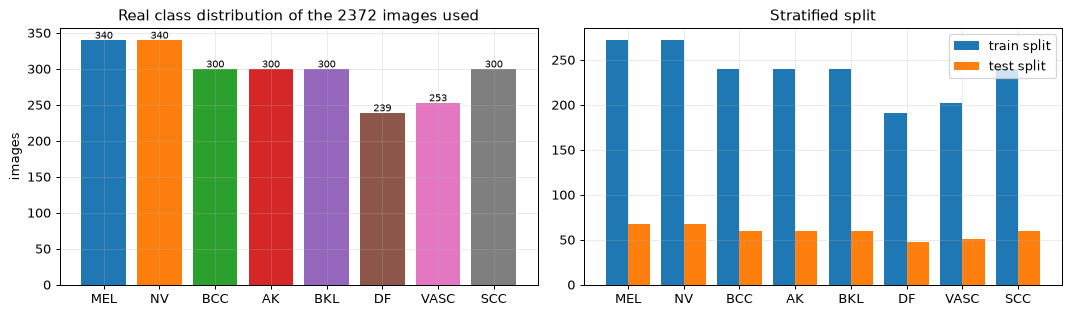

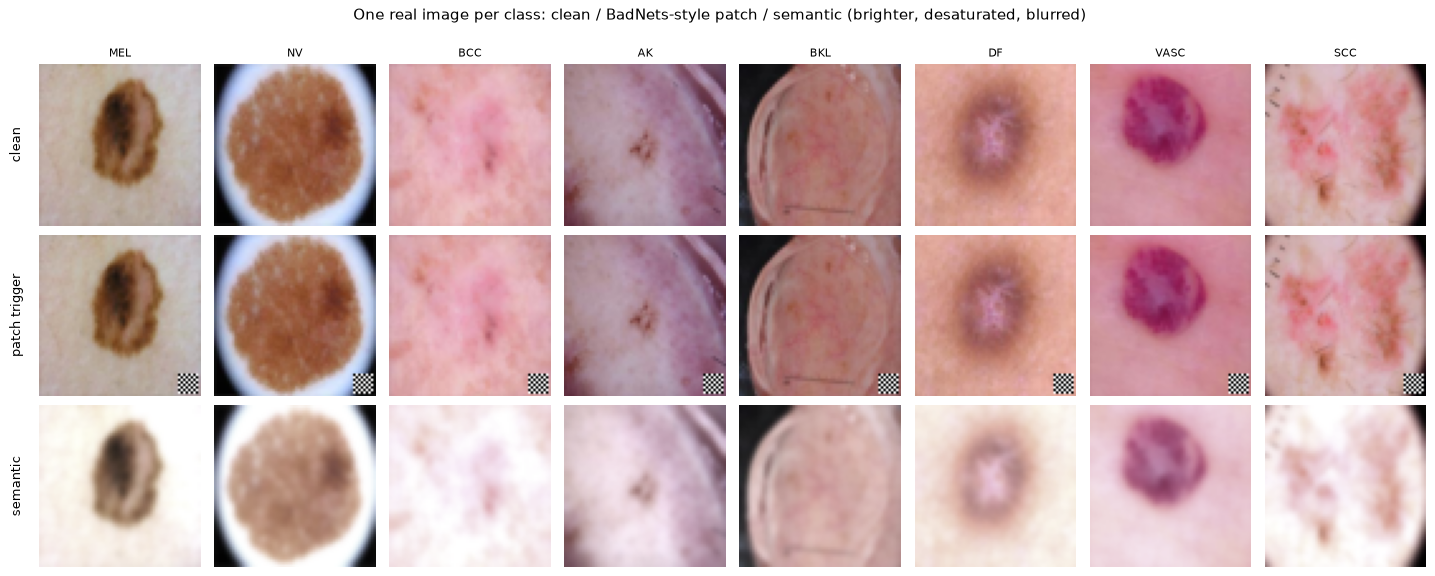

In [6]:
print("dataset: ISIC 2019 dermoscopic images (Hugging Face mirror", HF_DATASET + "), class-capped random subset")
print("image array shape:", X_img.shape, "(N, height, width, RGB), dtype", X_img.dtype)
print("feature matrix shape:", F_clean.shape, "-> 512 pooled channels of the last ResNet-18 stage: 'resnet18.layer4[channel 0..511]'")
print("raw pixel features:", X_img.shape[1] * X_img.shape[2] * X_img.shape[3], "values per image")
print("\noriginal label values in the mirror -> class:")
counts = np.bincount(y_all, minlength=NCLS)
print(pd.DataFrame({"label": range(NCLS), "class": CLASS_NAMES, "short": SHORT, "images": counts,
                    "train": np.bincount(y_all[tr_idx], minlength=NCLS), "test": np.bincount(y_all[te_idx], minlength=NCLS)}).to_string(index=False))
print("\nNote: the paper's Kaggle copy has 9 classes (it keeps Seborrheic Keratosis separate); ISIC 2019 merges it into 'Benign keratosis'.")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(SHORT, counts, color=plt.cm.tab10(np.arange(NCLS)))
ax[0].set_title(f"Real class distribution of the {N} images used"); ax[0].set_ylabel("images")
for i, v in enumerate(counts): ax[0].text(i, v + 2, str(v), ha="center", fontsize=8)
w_ = 0.4; xs = np.arange(NCLS)
ax[1].bar(xs - w_ / 2, np.bincount(y_all[tr_idx], minlength=NCLS), w_, label="train split")
ax[1].bar(xs + w_ / 2, np.bincount(y_all[te_idx], minlength=NCLS), w_, label="test split")
ax[1].set_xticks(xs); ax[1].set_xticklabels(SHORT); ax[1].legend(); ax[1].set_title("Stratified split")
plt.tight_layout(); plt.show()

# a few real images per class (what the model sees: 64x64) plus the two triggers applied to the same images
fig, axes = plt.subplots(3, NCLS, figsize=(2 * NCLS, 6.4))
for c in range(NCLS):
    i = int(np.where(y_all == c)[0][0])
    axes[0, c].imshow(X_img[i]); axes[0, c].set_title(SHORT[c], fontsize=9)
    axes[1, c].imshow(apply_patch(X_img[i:i + 1])[0])
    axes[2, c].imshow(semantic_transform(X_img[i]))
for a in axes.ravel(): a.axis("off")
axes[0, 0].text(-0.1, 0.5, "clean", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.1, 0.5, "patch trigger", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
axes[2, 0].text(-0.1, 0.5, "semantic", transform=axes[2, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle("One real image per class: clean / BadNets-style patch / semantic (brighter, desaturated, blurred)", y=1.0)
plt.tight_layout(); plt.show()

### 2-D scatter of the real observations (ground-truth colours)

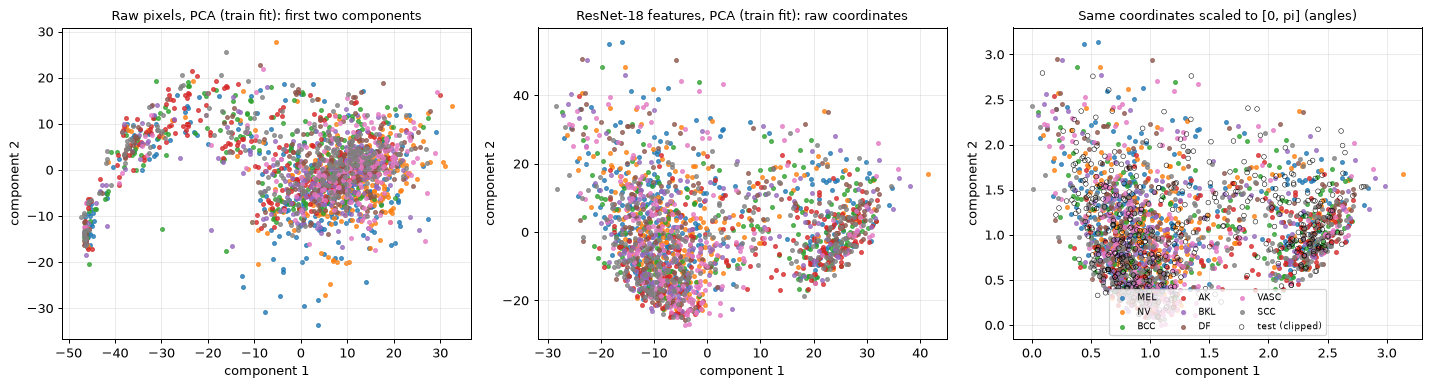

explained variance ratio of the 2 feature components: [0.167 0.14 ] - the classes overlap strongly in 2-D, which is why a 6-qubit head on 512 features is a hard task.


In [7]:
# 2-D projections of the REAL images, coloured by the ground-truth class. All fits use the training split only.
cmap = plt.cm.tab10
def scatter(ax, Z, y, title):
    for c in range(NCLS):
        m = y == c
        ax.scatter(Z[m, 0], Z[m, 1], s=9, color=cmap(c), label=SHORT[c], alpha=0.75)
    ax.set_title(title, fontsize=10)

# (a) raw pixels -> PCA (fitted on the training split)
pca_px = PCA(n_components=2, random_state=SEED).fit(X_img[tr_idx].reshape(len(tr_idx), -1).astype(np.float32) / 255)
Zpx_tr = pca_px.transform(X_img[tr_idx].reshape(len(tr_idx), -1).astype(np.float32) / 255)
# (b) ResNet-18 features -> PCA, then (c) the same coordinates scaled to [0, pi] (the range an angle encoding would use)
pca_ft = PCA(n_components=2, random_state=SEED).fit(F_clean[tr_idx])
Zft_tr, Zft_te = pca_ft.transform(F_clean[tr_idx]), pca_ft.transform(F_clean[te_idx])
mm = MinMaxScaler((0, np.pi)).fit(Zft_tr)
A_tr, A_te = mm.transform(Zft_tr), np.clip(mm.transform(Zft_te), 0, np.pi)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
scatter(ax[0], Zpx_tr, y_all[tr_idx], "Raw pixels, PCA (train fit): first two components")
scatter(ax[1], Zft_tr, y_all[tr_idx], "ResNet-18 features, PCA (train fit): raw coordinates")
scatter(ax[2], A_tr, y_all[tr_idx], "Same coordinates scaled to [0, pi] (angles)")
ax[2].scatter(A_te[:, 0], A_te[:, 1], s=14, facecolors="none", edgecolors="k", linewidths=0.4, label="test (clipped)")
ax[2].legend(fontsize=7, ncol=3, loc="lower center")
for a in ax: a.set_xlabel("component 1"); a.set_ylabel("component 2")
plt.tight_layout(); plt.show()
print("explained variance ratio of the 2 feature components:", pca_ft.explained_variance_ratio_.round(3),
      "- the classes overlap strongly in 2-D, which is why a 6-qubit head on 512 features is a hard task.")

## Quantum Circuit Architecture

The only quantum model in the paper is the variational circuit inside the hybrid network. The paper describes it in words and in Fig. 2 (a picture of a circuit whose width and depth are not stated); the cell below defines it as a PennyLane `QNode` and **draws exactly that QNode** with `qml.draw_mpl`:

* **Encoding module** `E(x)`: one `RY(q_i)` per qubit, where `q = tanh(W f + b) * pi/2` are the angles produced by the classical linear layer (paper Section 4.1).
* **Trainable module** `W(phi)`: per layer, an `RX`, `RY`, `RZ` rotation on every qubit (the paper lists RY, RZ, RX) followed by a ring of CNOTs.
* **Read-out**: the Pauli-Z expectation value of every qubit, a vector in [-1, 1]^6 that goes to a classical linear layer and a softmax (Section 4.2).

*Assumptions where the paper is silent:* 6 qubits, 2 trainable layers, rotation order RX -> RY -> RZ, CNOT ring `i -> i+1 (mod 6)`, one RY-encoding block (no data re-uploading). Only one circuit architecture is trained, so there is one drawing. The drawn circuit is the one the federated training uses (through its exact torch twin, section 3b, which is asserted equal to this QNode).

Matplotlib is building the font cache; this may take a moment.


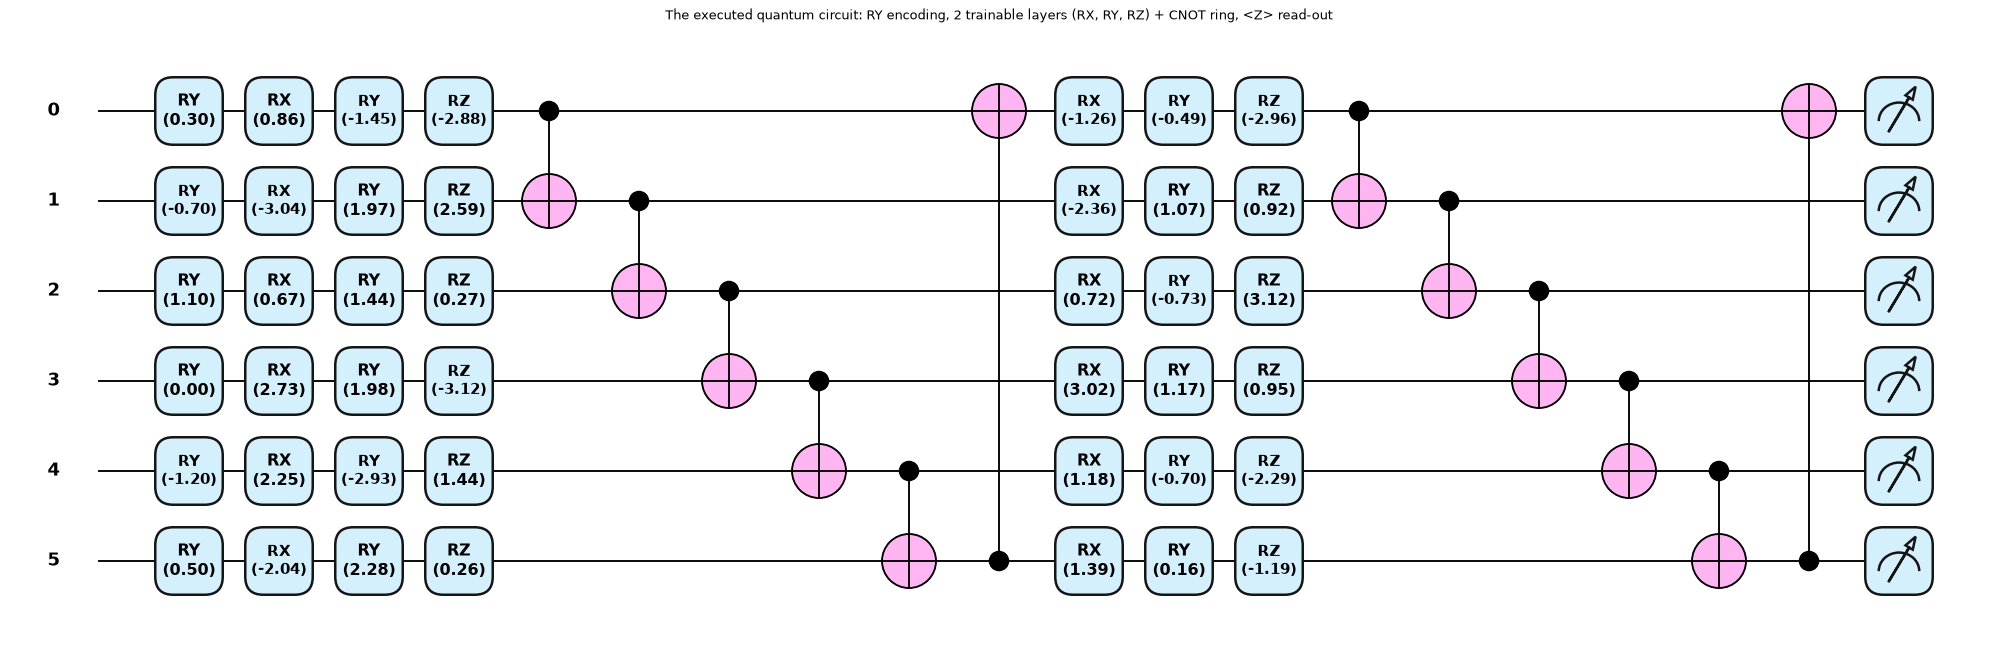

qubits: 6 | circuit depth: 19 | gates: 54 | trainable circuit parameters: 36 (+6 data-encoding angles per sample)
assumptions where the paper is silent: 6 qubits, 2 layers, RX-RY-RZ per qubit, CNOT ring, RY encoding of tanh(.)*pi/2 angles, <Z> on every qubit


In [8]:
# The variational quantum circuit (VQC) of the hybrid model, written as the PennyLane QNode that defines it.
dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="torch", diff_method="backprop")
def vqc_qnode(x, w):
    """x: (..., N_QUBITS) angles in [-pi/2, pi/2]; w: (N_LAYERS, N_QUBITS, 3) trainable angles."""
    for i in range(N_QUBITS):                        # encoding module E(x): one RY per qubit
        qml.RY(x[..., i], wires=i)
    for l in range(N_LAYERS):                        # trainable module W(phi): RX, RY, RZ per qubit + CNOT ring
        for i in range(N_QUBITS):
            qml.RX(w[l, i, 0], wires=i)
            qml.RY(w[l, i, 1], wires=i)
            qml.RZ(w[l, i, 2], wires=i)
        for i in range(N_QUBITS):
            qml.CNOT(wires=[i, (i + 1) % N_QUBITS])
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]    # <Z_i> in [-1, 1]

x0 = torch.tensor([0.3, -0.7, 1.1, 0.0, -1.2, 0.5][:N_QUBITS], dtype=torch.float64)
w0 = torch.tensor(np.random.default_rng(0).uniform(-np.pi, np.pi, (N_LAYERS, N_QUBITS, 3)))
fig, ax = qml.draw_mpl(vqc_qnode, decimals=2, style="pennylane")(x0, w0)
fig.suptitle("The executed quantum circuit: RY encoding, 2 trainable layers (RX, RY, RZ) + CNOT ring, <Z> read-out", y=1.02, fontsize=10)
plt.show()

specs = qml.specs(vqc_qnode)(x0, w0)
res = specs["resources"]
n_params = int(w0.numel())
print(f"qubits: {N_QUBITS} | circuit depth: {res.depth} | gates: {res.num_gates} | trainable circuit parameters: {n_params} "
      f"(+{N_QUBITS} data-encoding angles per sample)")
print("assumptions where the paper is silent: 6 qubits, 2 layers, RX-RY-RZ per qubit, CNOT ring, RY encoding of tanh(.)*pi/2 angles, <Z> on every qubit")

### 3b. An exact, fast twin of the QNode (used for the thousands of federated training steps)

A PennyLane `default.qubit` call costs about 0.15 s per step regardless of batch size, because the quantum tape is rebuilt each time. Federated training needs tens of thousands of steps. The circuit has only 6 qubits (64 amplitudes), so its unitary can be built exactly with a few differentiable matrix products in torch. The cell below does that and then **asserts** that the twin gives the same expectation values as the QNode above, and the same gradients with respect to the circuit weights and the input angles. Nothing is approximated.

In [9]:
# A PennyLane default.qubit call costs ~0.15 s per training step (tape construction), too slow for thousands of
# federated steps. The circuit is tiny, so the same unitary is built exactly with torch (differentiable) and
# ASSERTED equal to the QNode above, in values and in gradients.
CD = torch.complex128

def _rot_mats(w):
    """Vectorised single-qubit gates: w (L, Q, 3) -> (L, Q, 2, 2) matrices RZ(w2) @ RY(w1) @ RX(w0) (RX is applied first),
    written in closed form to keep the number of tiny torch operations low."""
    a, b, g = w[..., 0] / 2, w[..., 1] / 2, w[..., 2] / 2
    ca, sa, cb, sb = torch.cos(a), torch.sin(a), torch.cos(b), torch.sin(b)
    A, B, C, D = cb * ca, sb * sa, cb * sa, sb * ca
    em = torch.complex(torch.cos(g), -torch.sin(g)); ep = em.conj()                   # exp(-i g/2), exp(+i g/2)
    m00, m01 = em * torch.complex(A, B), em * torch.complex(-D, -C)
    m10, m11 = ep * torch.complex(D, -C), ep * torch.complex(A, -B)
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def _cnot_ring_perm(n):
    """Permutation matrix of CNOT(0,1) CNOT(1,2) ... CNOT(n-1,0) in the PennyLane ordering (wire 0 = most significant bit)."""
    P = torch.zeros(2 ** n, 2 ** n, dtype=CD)
    for b in range(2 ** n):
        bits = [(b >> (n - 1 - i)) & 1 for i in range(n)]
        for i in range(n):
            bits[(i + 1) % n] ^= bits[i]
        out = sum(v << (n - 1 - i) for i, v in enumerate(bits))
        P[out, b] = 1
    return P

_P = _cnot_ring_perm(N_QUBITS)
_Z = torch.tensor([[1 - 2 * ((b >> (N_QUBITS - 1 - i)) & 1) for i in range(N_QUBITS)] for b in range(2 ** N_QUBITS)],
                  dtype=torch.float64)

def vqc_fast(x, w):
    """x: (B, N_QUBITS), w: (N_LAYERS, N_QUBITS, 3)  ->  (B, N_QUBITS) expectation values <Z_i>."""
    x, w = x.double(), w.double()
    B = x.shape[0]
    R = _rot_mats(w)                                                        # (L, Q, 2, 2)
    K = R[:, 0]
    for i in range(1, N_QUBITS):                                            # Kronecker product over the qubits, all layers at once
        d = K.shape[-1]
        K = torch.einsum("lab,lcd->lacbd", K, R[:, i]).reshape(N_LAYERS, 2 * d, 2 * d)
    U = torch.eye(2 ** N_QUBITS, dtype=CD)
    for l in range(N_LAYERS):
        U = _P @ K[l] @ U                                                   # rotations, then the CNOT ring
    psi = torch.ones(B, 1, dtype=torch.float64)
    for i in range(N_QUBITS):                                               # product state of RY(x_i)|0>
        v = torch.stack([torch.cos(x[:, i] / 2), torch.sin(x[:, i] / 2)], dim=1)
        psi = (psi[:, :, None] * v[:, None, :]).reshape(B, -1)
    psi = psi.to(CD) @ U.T
    return ((psi.abs() ** 2) @ _Z).float()

# ---- equivalence assertions: values and gradients, several random batches ----
g = torch.Generator().manual_seed(1)
xt = (torch.rand(7, N_QUBITS, generator=g, dtype=torch.float64) - 0.5) * np.pi
wt = ((torch.rand(N_LAYERS, N_QUBITS, 3, generator=g, dtype=torch.float64) - 0.5) * 2 * np.pi).requires_grad_(True)
xt = xt.requires_grad_(True)
ref = torch.stack(vqc_qnode(xt, wt), dim=-1)
fast = vqc_fast(xt, wt).double()
assert torch.allclose(ref, fast, atol=1e-5), float((ref - fast).abs().max())
gr_ref = torch.autograd.grad(ref.sum(), [wt, xt])
gr_fast = torch.autograd.grad(vqc_fast(xt, wt).double().sum(), [wt, xt])
for a, b in zip(gr_ref, gr_fast):
    assert torch.allclose(a, b, atol=1e-5), float((a - b).abs().max())
print("fast torch simulator == PennyLane QNode: max |value diff| =", float((ref - fast).abs().max()),
      "| gradients w.r.t. weights and inputs agree")

fast torch simulator == PennyLane QNode: max |value diff| = 3.57459334354715e-09 | gradients w.r.t. weights and inputs agree


## 3. The trainable model and its classical twins

Three heads sit on the same 512 frozen features (all with the same fixed input standardisation fitted on the clean server-side set):

* **hybrid** (the paper's QCFL head): `Linear(512 -> 6)`, `tanh * pi/2`, the 6-qubit circuit with 36 trainable angles, `Linear(6 -> 8)`, softmax (inside the cross-entropy). 3,170 trainable parameters.
* **bottleneck** (classical twin): the circuit is replaced by `Linear(6 -> 6) + tanh`, same width everywhere else. This isolates the effect of the quantum layer.
* **linear** (the "classical ResNet-18" of the paper, with a frozen backbone): `Linear(512 -> 8)`.

`mask` is a gate over the 512 channels, used by the pruning-type defences. Metrics follow the paper: accuracy, precision, recall, F1 (macro), and the **backdoor attack rate (BAR)** defined in the table above.

In [10]:
# Fixed input standardisation of the 512 ResNet features, fitted on the clean server-side defence set (training split only)
FEAT_MU = torch.from_numpy(F_clean[def_idx].mean(0)).float()
FEAT_SD = torch.from_numpy(F_clean[def_idx].std(0) + 1e-3).float()

class Head(nn.Module):
    """Trainable part on top of the frozen ResNet-18 features (512-d).
    kind='hybrid'     : Linear(512,Q) -> tanh*pi/2 -> VQC (PennyLane-equivalent) -> x gain -> Linear(Q,8)      [the paper's QFL model]
    kind='bottleneck' : Linear(512,Q) -> tanh*pi/2 -> Linear(Q,Q)+tanh                              [classical twin, same width]
    kind='linear'     : Linear(512,8)                                                               [plain classical ResNet-18 head]
    `mask` is a 512-channel gate applied to the features (used by Fine-Pruning and Spectral Defense)."""
    def __init__(self, kind="hybrid"):
        super().__init__()
        self.kind = kind
        self.register_buffer("mask", torch.ones(512))
        self.register_buffer("mu", FEAT_MU.clone()); self.register_buffer("sd", FEAT_SD.clone())
        if kind == "linear":
            self.fc = nn.Linear(512, NCLS)
        else:
            self.pre = nn.Linear(512, N_QUBITS)
            if kind == "hybrid":
                self.qw = nn.Parameter(torch.empty(N_LAYERS, N_QUBITS, 3).uniform_(-np.pi, np.pi) * 0.5)
            else:
                self.mid = nn.Linear(N_QUBITS, N_QUBITS)
            self.post = nn.Linear(N_QUBITS, NCLS)

    def norm(self, f):
        return ((f - self.mu) / self.sd) * self.mask                          # standardise, then channel gate

    def angles(self, f):
        return torch.tanh(self.pre(self.norm(f))) * (np.pi / 2)             # q_in = tanh(W f + b) * pi/2

    def forward(self, f):
        if self.kind == "linear":
            return self.fc(self.norm(f))
        a = self.angles(f)
        h = READOUT_GAIN * vqc_fast(a, self.qw) if self.kind == "hybrid" else torch.tanh(self.mid(a))
        return self.post(h)                                                  # softmax is inside the cross-entropy

def n_params(m): return sum(p.numel() for p in m.parameters())
def get_vec(m): return torch.nn.utils.parameters_to_vector(m.parameters()).detach().clone()
def set_vec(m, v): torch.nn.utils.vector_to_parameters(v.clone(), m.parameters())

def make_head(kind, vec=None, mask=None, seed=None):
    if seed is not None: torch.manual_seed(seed)
    h = Head(kind)
    if vec is not None: set_vec(h, vec)
    if mask is not None: h.mask.copy_(mask)
    return h

for k in ("hybrid", "bottleneck", "linear"):
    print(f"{k:11s} trainable parameters: {n_params(Head(k))}")

T = lambda a: torch.from_numpy(np.ascontiguousarray(a)).float()

@torch.no_grad()
def predict(head, Xf):
    head.eval()
    return head(T(Xf)).argmax(1).numpy()

def metrics(head, Xf, y):
    p = predict(head, Xf)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return dict(acc=accuracy_score(y, p), prec=pr, rec=rc, f1=f1)

def bar_trigger(head, idx_test):
    """Backdoor attack rate (BAR) of the patch trigger: share of triggered non-target test images classified as the target."""
    ii = idx_test[y_all[idx_test] != TARGET_TRIGGER]
    return float((predict(head, F_trig[ii]) == TARGET_TRIGGER).mean())

def bar_semantic(head, idx_test):
    """BAR of the semantic trigger: share of re-lit test Nevus images classified as Melanoma."""
    ii = idx_test[y_all[idx_test] == SOURCE_SEM]
    return float((predict(head, F_sem[ii]) == TARGET_SEM).mean())

def bar(head, attack, idx_test=None):
    idx_test = te_idx if idx_test is None else idx_test
    return {"trigger": bar_trigger, "semantic": bar_semantic}[attack](head, idx_test) if attack in ("trigger", "semantic") else float("nan")

hybrid      trainable parameters: 3170
bottleneck  trainable parameters: 3176
linear      trainable parameters: 4104


## 4. Federated learning with four aggregation rules, IID and non-IID shards, and the two attackers

The cell below implements, on flat parameter vectors, the four rules of the paper (Section 4.3):

* **FedAvg**: the server averages the clients' models, weighted by their number of images.
* **FedProx**: each client adds `mu/2 * ||w - w_global||^2` to its loss, which pulls local models back towards the global one.
* **FedNova**: clients with more local steps would otherwise dominate; every client's update is divided by its number of local steps `tau_k`, averaged, and multiplied by the effective number of steps.
* **SCAFFOLD**: every client keeps a control variate `c_i` and the server one `c`; local gradients are corrected by `- c_i + c` so that client drift is cancelled, and `c_i` is refreshed from the realised update.

A **scenario** fixes the data split (IID: equal random shards; non-IID: for each class the share going to each client is drawn from a Dirichlet distribution, so clients hold very different class mixes), and the attack. The attacker owns the two clients with most Nevus images: *trigger* = 50 % extra copies of its images carrying the patch and labelled Nevus; *semantic* = copies of its Nevus images in the re-lit style, labelled Melanoma. The attacker follows the normal training protocol afterwards (no update boosting). Next cell: the class mix per client (paper Fig. 6).

In [11]:
# ---------------- non-IID partition (Dirichlet over class proportions) ----------------
def partition(labels, K, kind, rng_):
    n = len(labels)
    if kind == "iid":
        perm = rng_.permutation(n)
        return [a.tolist() for a in np.array_split(perm, K)]
    while True:
        parts = [[] for _ in range(K)]
        for c in range(NCLS):
            ids = np.where(labels == c)[0]; rng_.shuffle(ids)
            p = rng_.dirichlet(DIRICHLET_ALPHA * np.ones(K))
            cuts = (np.cumsum(p) * len(ids)).astype(int)[:-1]
            for k, chunk in enumerate(np.split(ids, cuts)):
                parts[k] += chunk.tolist()
        if min(len(p) for p in parts) >= 12:
            return parts

def jsd_to_global(parts, labels):
    g = np.bincount(labels, minlength=NCLS) / len(labels)
    vals = []
    for p in parts:
        h = np.bincount(labels[p], minlength=NCLS) / max(1, len(p))
        vals.append(jensenshannon(h, g, base=2) ** 2)
    return float(np.mean(vals)), vals

_SCEN = {}
def scenario(split, attack, seed):
    """Build clients for (iid|noniid, none|trigger|semantic, seed). Returns a dict with the client data (features) and pool."""
    key = (split, attack, seed)
    if key in _SCEN: return _SCEN[key]
    r = np.random.default_rng(seed)
    labels = y_all[pool_idx]
    parts = partition(labels, N_CLIENTS, split, r)
    # CHOICE: the adversary controls the clients that hold most source-class images (attack can only use local data)
    src = TARGET_TRIGGER if attack == "trigger" else SOURCE_SEM
    cnt = [int((labels[p] == src).sum()) for p in parts]
    mal = set(np.argsort(cnt)[::-1][:N_MALICIOUS].tolist()) if attack in ("trigger", "semantic") else set()
    clients = []
    for k, p in enumerate(parts):
        gi = pool_idx[p]
        X, y = F_clean[gi], y_all[gi]
        pois = np.zeros(len(gi), bool)
        if k in mal:
            if attack == "trigger":
                cand = np.where(y_all[gi] != TARGET_TRIGGER)[0]
                sel = r.choice(cand, size=min(len(cand), int(POISON_FRAC * len(gi))), replace=False)
                Xp, yp = F_trig[gi[sel]], np.full(len(sel), TARGET_TRIGGER)
            else:
                sel = np.where(y_all[gi] == SOURCE_SEM)[0]
                Xp, yp = F_sem[gi[sel]], np.full(len(sel), TARGET_SEM)
            X = np.concatenate([X, Xp]); y = np.concatenate([y, yp])
            pois = np.concatenate([pois, np.ones(len(sel), bool)])
        clients.append(dict(X=T(X), y=torch.from_numpy(y).long(), pois=pois, mal=k in mal, gi=gi))
    pool_X = np.concatenate([c["X"].numpy() for c in clients]); pool_y = np.concatenate([c["y"].numpy() for c in clients])
    pool_p = np.concatenate([c["pois"] for c in clients])
    jsd, _ = jsd_to_global(parts, labels)
    out = dict(clients=clients, mal=sorted(mal), parts=parts, jsd=jsd, pool_X=pool_X, pool_y=pool_y, pool_p=pool_p)
    _SCEN[key] = out
    return out

# ---------------- federated algorithms: FedAvg, FedProx, FedNova, SCAFFOLD ----------------
def local_update(model, w_g, c, algo, ctx):
    X, y = c["X"], c["y"]
    set_vec(model, w_g)
    params = list(model.parameters())
    w = w_g.clone(); tau = 0
    gen = np.random.default_rng(ctx["seed_local"])
    for _ in range(LOCAL_EPOCHS):
        perm = gen.permutation(len(y))
        for s in range(0, len(y), BATCH):
            ii = perm[s:s + BATCH]
            loss = F.cross_entropy(model(X[ii]), y[ii])
            for p in params: p.grad = None
            loss.backward()
            g = torch.cat([p.grad.flatten() for p in params])
            if algo == "fedprox": g = g + FEDPROX_MU * (w - w_g)
            if algo == "scaffold": g = g - ctx["c_i"] + ctx["c_g"]
            w = w - LR * g
            torch.nn.utils.vector_to_parameters(w.clone(), params)
            tau += 1
    return w, tau

def run_fl(split, attack, algo, kind="hybrid", seed=42, rounds=None, keep_hist=True):
    rounds = ROUNDS if rounds is None else rounds
    sc = scenario(split, attack, seed)
    clients = sc["clients"]; K = len(clients)
    model = make_head(kind, seed=seed)
    w_g = get_vec(model)
    n_k = np.array([len(c["y"]) for c in clients], float); p_k = n_k / n_k.sum()
    c_g = torch.zeros_like(w_g); c_i = [torch.zeros_like(w_g) for _ in range(K)]
    hist = []; t0 = time.time()
    for rd in range(rounds):
        locs, taus, dcs = [], [], []
        for k, c in enumerate(clients):
            ctx = dict(seed_local=seed * 100003 + rd * 101 + k, c_g=c_g, c_i=c_i[k])
            w_k, tau = local_update(model, w_g, c, algo, ctx)
            locs.append(w_k); taus.append(tau)
            if algo == "scaffold":
                c_new = c_i[k] - c_g + (w_g - w_k) / (LR * tau)
                dcs.append(c_new - c_i[k]); c_i[k] = c_new
        locs = torch.stack(locs); taus = np.array(taus, float)
        P = torch.tensor(p_k, dtype=torch.float32)
        if algo in ("fedavg", "fedprox"):
            w_g = (P[:, None] * locs).sum(0)
        elif algo == "fednova":
            d = (w_g[None] - locs) / torch.tensor(taus, dtype=torch.float32)[:, None]      # normalised updates
            w_g = w_g - float((p_k * taus).sum()) * (P[:, None] * d).sum(0)
        elif algo == "scaffold":
            w_g = w_g + (locs - w_g[None]).mean(0)                                        # global step size 1
            c_g = c_g + torch.stack(dcs).mean(0)
        if keep_hist:
            h = make_head(kind, w_g)
            m = metrics(h, F_clean[te_idx], y_all[te_idx])
            hist.append(dict(round=rd + 1, acc=m["acc"], bar=bar(h, attack)))
    h = make_head(kind, w_g)
    m = metrics(h, F_clean[te_idx], y_all[te_idx])
    m.update(bar=bar(h, attack), time=time.time() - t0, w=w_g, hist=pd.DataFrame(hist), split=split, attack=attack,
             algo=algo, kind=kind, seed=seed)
    return m

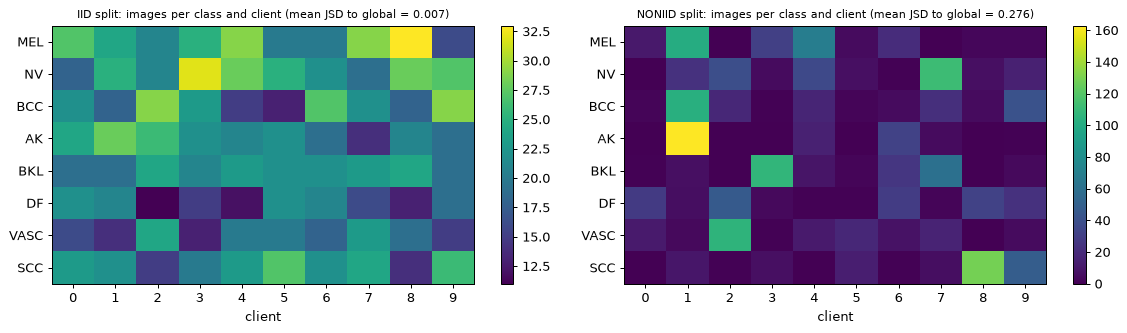

iid     trigger   malicious clients [3, 8] | poisoned copies per malicious client: [85, 85] | client sizes: [171, 171, 171, 256, 171, 171, 171, 170, 255, 170]
iid     semantic  malicious clients [3, 8] | poisoned copies per malicious client: [32, 28] | client sizes: [171, 171, 171, 203, 171, 171, 171, 170, 198, 170]
noniid  trigger   malicious clients [2, 7] | poisoned copies per malicious client: [105, 111] | client sizes: [54, 417, 315, 156, 159, 49, 123, 334, 176, 140]
noniid  semantic  malicious clients [2, 7] | poisoned copies per malicious client: [39, 112] | client sizes: [54, 417, 249, 156, 159, 49, 123, 335, 176, 140]


In [12]:
# Non-IID shards (paper Fig. 6): class mix of every client under a Dirichlet split, and how skewed it is (Jensen-Shannon divergence)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, split in zip(ax, ("iid", "noniid")):
    sc = scenario(split, "none", SEED)
    M = np.array([np.bincount(y_all[pool_idx][p], minlength=NCLS) for p in sc["parts"]]).T
    im = a.imshow(M, cmap="viridis", aspect="auto")
    a.set_xticks(range(N_CLIENTS)); a.set_yticks(range(NCLS)); a.set_yticklabels(SHORT)
    a.set_xlabel("client"); a.set_title(f"{split.upper()} split: images per class and client (mean JSD to global = {sc['jsd']:.3f})", fontsize=9)
    a.grid(False); plt.colorbar(im, ax=a)
plt.tight_layout(); plt.show()
for split in ("iid", "noniid"):
    for attack in ("trigger", "semantic"):
        sc = scenario(split, attack, SEED)
        print(f"{split:7s} {attack:9s} malicious clients {sc['mal']} | poisoned copies per malicious client:",
              [int(c['pois'].sum()) for c in sc['clients'] if c['mal']], "| client sizes:", [len(c['y']) for c in sc['clients']])

### Experiment A: which aggregation rule resists which attack?

For every (data split, attack, aggregation rule) the federation is trained from the same initial weights and the same shards. We report the global model's accuracy on the clean test set and the BAR. Because a "successful" attack must be judged against what a *clean* federation does with the same inputs (a re-lit Nevus is sometimes simply called Melanoma; a patch may push some images to Nevus by chance), the control table gives that **base rate** from the no-attack federation.

In [13]:
# Experiment A: federated training of the hybrid model, 4 aggregation rules x {IID, non-IID} x {no attack, trigger, semantic}
RUNS = {}
rows = []
for split, algos in (("iid", ALGOS_IID), ("noniid", ALGOS_NONIID)):
    for attack in ("none", "trigger", "semantic"):
        for algo in algos:
            r = run_fl(split, attack, algo, "hybrid", SEED)
            RUNS[(split, attack, algo)] = r
            rows.append(dict(split=split, attack=attack, algo=algo, acc=r["acc"], f1=r["f1"], BAR=r["bar"], secs=r["time"]))
            print(f"{split:7s} {attack:9s} {algo:9s} acc={r['acc']:.3f} f1={r['f1']:.3f} BAR={r['bar']:.3f} ({r['time']:.0f}s)", flush=True)
dfA = pd.DataFrame(rows)

# control: BAR of the CLEAN federation on the triggered / re-lit test images (the base rate a "successful" attack must beat)
ctrl = []
for split in dfA.split.unique():
    for algo in dfA[dfA.split == split].algo.unique():
        h = make_head("hybrid", RUNS[(split, "none", algo)]["w"])
        ctrl.append(dict(split=split, algo=algo, base_rate_trigger=bar_trigger(h, te_idx), base_rate_semantic=bar_semantic(h, te_idx)))
dfCtrl = pd.DataFrame(ctrl)
piv = dfA.pivot_table(index=["split", "algo"], columns="attack", values=["acc", "BAR"])
print("\nGlobal test accuracy and backdoor attack rate (BAR):")
print(piv.round(3).to_string())
print("\nControl (clean federation, no attacker): share of triggered / re-lit test images that land in the target class anyway")
print(dfCtrl.round(3).to_string(index=False))

iid     none      fedavg    acc=0.286 f1=0.266 BAR=nan (140s)


iid     trigger   fedavg    acc=0.307 f1=0.283 BAR=0.260 (192s)


iid     semantic  fedavg    acc=0.295 f1=0.282 BAR=0.662 (160s)


noniid  none      fedavg    acc=0.295 f1=0.219 BAR=nan (111s)


noniid  none      fedprox   acc=0.297 f1=0.255 BAR=nan (140s)


...

noniid  semantic  fedavg    acc=0.375 f1=0.324 BAR=0.838 (84s)


noniid  semantic  fedprox   acc=0.276 f1=0.213 BAR=0.956 (111s)


noniid  semantic  fednova   acc=0.341 f1=0.304 BAR=0.750 (114s)


noniid  semantic  scaffold  acc=0.272 f1=0.237 BAR=0.721 (135s)



Global test accuracy and backdoor attack rate (BAR):
                     BAR            acc                 
attack          semantic trigger   none semantic trigger
split  algo                                             
iid    fedavg      0.662   0.260  0.286    0.295   0.307
noniid fedavg      0.838   0.440  0.295    0.375   0.284
       fednova     0.750   0.265  0.312    0.341   0.318
       fedprox     0.956   0.690  0.297    0.276   0.206
       scaffold    0.721   0.005  0.295    0.272   0.238

Control (clean federation, no attacker): share of triggered / re-lit test images that land in the target class anyway
 split     algo  base_rate_trigger  base_rate_semantic
   iid   fedavg              0.074               0.382
noniid   fedavg              0.265               0.235
noniid  fedprox              0.256               0.235
noniid  fednova              0.243               0.147
noniid scaffold              0.044               0.382


## 5. Classical baselines on exactly the same inputs

The paper states that the quantum-hybrid model beats the classical ResNet-18 in accuracy, precision, recall, F1 and training time (no numbers, Figs. 3-4 show per-class bars). Here the three heads are trained with the identical federation (FedAvg, clean, same shards and seeds) on the identical 512 frozen features, so any difference comes from the head alone. Training time is the wall-clock time of the whole federation on this CPU; the quantum layer is *simulated*, so a time advantage cannot appear. The last two plots are the per-class view of the paper's Figs. 3-4: F1 per diagnosis without and with an attacker.

Federated FedAvg, 20 rounds; non-IID: mean over seeds [42, 43, 44], IID: seed 42 (sd is NaN with a single seed):
                   params    acc  acc_sd   prec    rec     f1  f1_sd     secs
split  model                                                                 
iid    bottleneck    3176  0.406     NaN  0.396  0.404  0.391    NaN   21.357
       hybrid        3170  0.286     NaN  0.288  0.276  0.266    NaN  140.142
       linear        4104  0.480     NaN  0.488  0.485  0.485    NaN   10.985
noniid bottleneck    3176  0.366   0.035  0.353  0.360  0.347  0.054   19.486
       hybrid        3170  0.321   0.036  0.321  0.314  0.268  0.054  124.621
       linear        4104  0.444   0.015  0.449  0.447  0.445  0.016   10.141


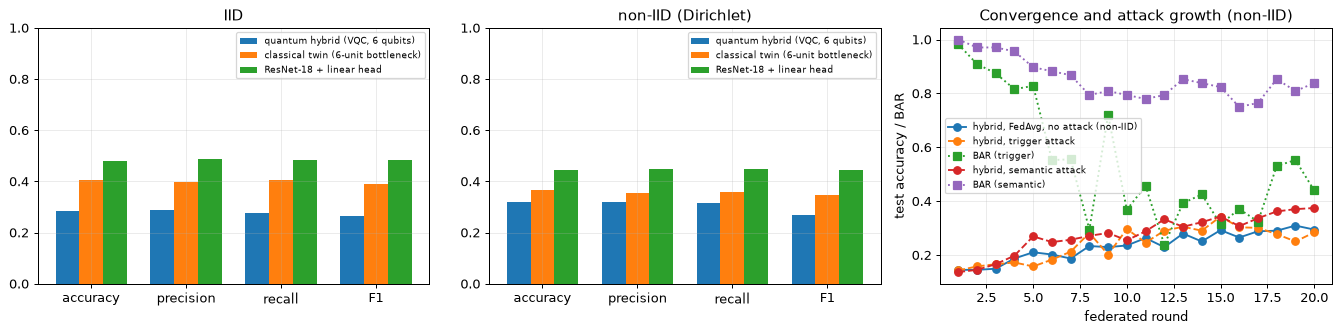

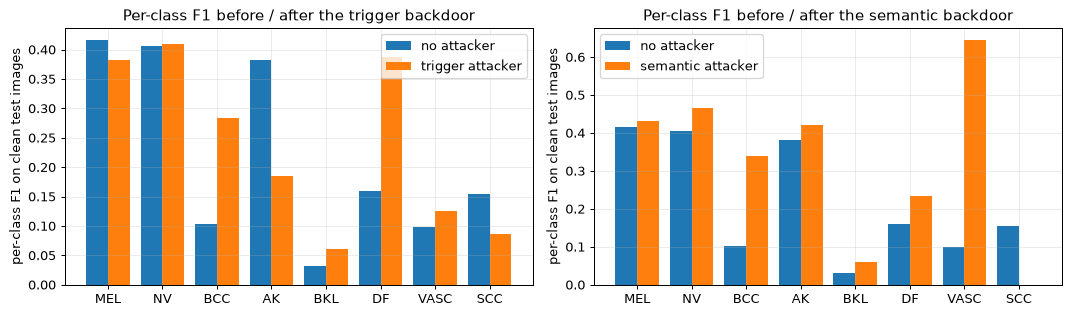

In [14]:
# Quantum-hybrid head vs classical heads, identical frozen ResNet-18 features, identical federation (FedAvg, no attacker)
rowsB = []
for split in ("iid", "noniid"):
    for kind in ("hybrid", "bottleneck", "linear"):
        for sd in (SEEDS if split == "noniid" else SEEDS[:1]):          # extra seeds only for the non-IID comparison (CPU budget)
            r = RUNS[(split, "none", "fedavg")] if (kind == "hybrid" and sd == SEED) else run_fl(split, "none", "fedavg", kind, sd, keep_hist=False)   # reuse Experiment A
            rowsB.append(dict(split=split, model=kind, seed=sd, params=n_params(Head(kind)), acc=r["acc"], prec=r["prec"],
                              rec=r["rec"], f1=r["f1"], secs=r["time"]))
dfB = pd.DataFrame(rowsB)
summ = dfB.groupby(["split", "model"]).agg(params=("params", "first"), acc=("acc", "mean"), acc_sd=("acc", "std"), prec=("prec", "mean"),
                                           rec=("rec", "mean"), f1=("f1", "mean"), f1_sd=("f1", "std"), secs=("secs", "mean")).round(3)
print(f"Federated FedAvg, {ROUNDS} rounds; non-IID: mean over seeds {SEEDS}, IID: seed {SEEDS[0]} (sd is NaN with a single seed):")
print(summ.to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
names = {"hybrid": f"quantum hybrid (VQC, {N_QUBITS} qubits)", "bottleneck": "classical twin (6-unit bottleneck)", "linear": "ResNet-18 + linear head"}
for a, (split, title) in zip(ax[:2], (("iid", "IID"), ("noniid", "non-IID (Dirichlet)"))):
    sub = summ.loc[split]
    xs = np.arange(4); wd = 0.25
    for j, kind in enumerate(("hybrid", "bottleneck", "linear")):
        a.bar(xs + (j - 1) * wd, sub.loc[kind, ["acc", "prec", "rec", "f1"]].values, wd, label=names[kind])
    a.set_xticks(xs); a.set_xticklabels(["accuracy", "precision", "recall", "F1"]); a.set_ylim(0, 1); a.set_title(title); a.legend(fontsize=7)
r = RUNS[("noniid", "none", "fedavg")]["hist"]
ax[2].plot(r["round"], r["acc"], "o-", label="hybrid, FedAvg, no attack (non-IID)")
for attack in ("trigger", "semantic"):
    rr = RUNS[("noniid", attack, "fedavg")]["hist"]
    ax[2].plot(rr["round"], rr["acc"], "o--", label=f"hybrid, {attack} attack")
    ax[2].plot(rr["round"], rr["bar"], "s:", label=f"BAR ({attack})")
ax[2].set_xlabel("federated round"); ax[2].set_ylabel("test accuracy / BAR"); ax[2].legend(fontsize=7); ax[2].set_title("Convergence and attack growth (non-IID)")
plt.tight_layout(); plt.show()

# per-class F1 before / after the backdoor (paper Figs. 3 and 4), non-IID FedAvg, hybrid
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, attack in zip(ax, ("trigger", "semantic")):
    f_clean = precision_recall_fscore_support(y_all[te_idx], predict(make_head("hybrid", RUNS[("noniid", "none", "fedavg")]["w"]), F_clean[te_idx]), labels=range(NCLS), zero_division=0)[2]
    f_att = precision_recall_fscore_support(y_all[te_idx], predict(make_head("hybrid", RUNS[("noniid", attack, "fedavg")]["w"]), F_clean[te_idx]), labels=range(NCLS), zero_division=0)[2]
    xs = np.arange(NCLS)
    a.bar(xs - 0.2, f_clean, 0.4, label="no attacker"); a.bar(xs + 0.2, f_att, 0.4, label=f"{attack} attacker")
    a.set_xticks(xs); a.set_xticklabels(SHORT); a.set_ylabel("per-class F1 on clean test images"); a.legend(); a.set_title(f"Per-class F1 before / after the {attack} backdoor")
plt.tight_layout(); plt.show()

## 6. The four defences

All defences start from the same attacked **FedAvg** global model and are judged by clean test accuracy and BAR afterwards ("PD" = post-defence in the paper's tables). Because the backbone is frozen, the defences act on the 512 pooled ResNet channels and the head; Neural Cleanse also needs the pixels and the backbone. The server holds a small clean **defence set** (about 10 % of the training split). Detection-style defences (Activation Clustering, Spectral) additionally look at the activations of the pooled client data, which a real server could not see: this is generous to them and is stated in the verdicts.

* **Fine-Pruning**: switch off the channels that are most dormant on clean defence images, as long as defence-set accuracy drops by less than 4 points, then fine-tune.
* **Activation Clustering**: for every class, project the activations of the pooled training data to 10 dimensions, split them in 2 clusters with k-means, and flag a class when the smaller cluster holds under 35 % of the data and the silhouette score exceeds 0.12; remove the flagged samples and retrain on the rest. Detection precision and recall against the known poisoned copies are printed.
* **Neural Cleanse**: for every class, optimise a pixel mask and pattern that turns clean images into that class with a small L1 mask norm; a class whose norm is an outlier (MAD anomaly index above 2) is flagged; "unlearn" by fine-tuning with the reversed trigger stamped on 20 % of defence images and the *true* labels. This needs a forward/backward pass through the ResNet and is the slowest step, hence the small step budget.
* **Spectral Defense (the paper's Algorithm 1)**: for every class compute the eigenvalues of the covariance of its activations; three numbers per class (spectral entropy, spectral variance, dominant-eigenvalue ratio) are turned into robust MAD z-scores and summed; classes above `tau` are suspicious; in those classes, channels active above `mu + 2 sigma` are scaled by 0.5; then the model is fine-tuned for `FT_EPOCHS` epochs with a loss `L_cls + L_adv`, where `L_adv` uses FGSM-perturbed features. Variant **"no clean data"**: instead of the clean defence set, the strongest spectral outliers (top 15 % along the first singular direction, as in "spectral signatures") of the flagged classes are removed and the rest of the pooled data is used for the fine-tuning, testing the abstract's claim of working "without recourse to clean validation data".
* **Control: plain fine-tune** of the attacked model on the clean defence set for the same number of epochs, without any defence logic. If the "repaired" accuracy of the paper (e.g. 47 % to 77 %) were due to the defence rather than to extra training, this control would not reach it.

In [15]:
# ====================== Defences (all act on the global model after federated training) ======================
# Server-side data: a small clean "defence set" (labels known) and, for the detection-style defences, the activations
# of the pooled client data as an oracle view (a real server could not see them; this is generous to AC and Spectral).

def finetune(w, Xf, yf, epochs, mask=None, kind="hybrid", adv_eps=0.0, seed=0, lr=None):
    """Plain SGD fine-tuning of the head; optional feature-space FGSM augmentation (adv_eps > 0)."""
    h = make_head(kind, w, mask); h.train()
    params = list(h.parameters()); X, y = T(Xf), torch.from_numpy(np.asarray(yf)).long()
    gen = np.random.default_rng(seed); lr = FT_LR if lr is None else lr
    for _ in range(epochs):
        perm = gen.permutation(len(y))
        for s in range(0, len(y), BATCH):
            ii = perm[s:s + BATCH]; xb, yb = X[ii], y[ii]
            loss = F.cross_entropy(h(xb), yb)
            if adv_eps > 0:                                           # L = L_cls + L_adv, x_adv = x + eps*sign(grad_x L)
                xa = xb.clone().requires_grad_(True)
                g, = torch.autograd.grad(F.cross_entropy(h(xa), yb), xa)
                loss = loss + F.cross_entropy(h(xb + adv_eps * g.sign()), yb)
            for p in params: p.grad = None
            loss.backward()
            with torch.no_grad():
                for p in params: p -= lr * p.grad
    return get_vec(h), h.mask.clone()

def evaluate_defended(w, mask, kind, attack):
    h = make_head(kind, w, mask)
    m = metrics(h, F_clean[te_idx], y_all[te_idx])
    return m["acc"], m["f1"], bar(h, attack)

# ---------------------------------------- Fine-Pruning (Liu et al. 2018) ----------------------------------------
def defence_fine_pruning(w, kind, attack, Xdef, ydef):
    h = make_head(kind, w); base = accuracy_score(ydef, predict(h, Xdef))
    order = np.argsort(Xdef.mean(0))                                  # dormant channels (lowest mean activation) first
    mask = torch.ones(512); best = mask.clone()
    for n in range(16, 410, 16):
        mk = torch.ones(512); mk[order[:n]] = 0
        if accuracy_score(ydef, predict(make_head(kind, w, mk), Xdef)) < base - 0.04: break
        best = mk
    w2, m2 = finetune(w, Xdef, ydef, FT_EPOCHS, mask=best, kind=kind, seed=1)
    return w2, m2, dict(pruned=int((best == 0).sum()))

# ------------------------------------ Activation Clustering (Chen et al. 2018) ------------------------------------
def defence_activation_clustering(w, kind, attack, Xpool, ypool, ppool, Xdef, ydef):
    flag = np.zeros(len(ypool), bool); flagged_classes = []
    for c in range(NCLS):
        ii = np.where(ypool == c)[0]
        if len(ii) < 20: continue
        z = PCA(n_components=min(10, len(ii) - 1), random_state=SEED).fit_transform(Xpool[ii])
        km = KMeans(2, n_init=5, random_state=SEED).fit(z)
        small = int(np.argmin(np.bincount(km.labels_, minlength=2)))
        rel = float((km.labels_ == small).mean()); sil = float(silhouette_score(z, km.labels_))
        if rel < 0.35 and sil > 0.12:                                 # CHOICE: thresholds (relative size, silhouette)
            flag[ii[km.labels_ == small]] = True; flagged_classes.append(c)
    keep = ~flag
    tp = int((flag & ppool).sum()); prec = tp / max(1, int(flag.sum())); rec = tp / max(1, int(ppool.sum()))
    w2, m2 = finetune(w, Xpool[keep], ypool[keep], FT_EPOCHS, kind=kind, seed=2)     # retrain on the filtered pooled data
    return w2, m2, dict(flagged=flagged_classes, removed=int(flag.sum()), det_precision=prec, det_recall=rec)

# --------------------------------------- Neural Cleanse (Wang et al. 2019) ---------------------------------------
def reverse_engineer(kind, w, Xdef_u8, target, steps, batch, seed):
    """Optimise a (mask, pattern) that flips clean images to `target`; returns mask, pattern, L1(mask)."""
    h = make_head(kind, w); h.eval()
    gen = np.random.default_rng(seed + target)
    mp = torch.full((1, 1, IMG_SIZE, IMG_SIZE), -2.0, requires_grad=True)      # sigmoid(-2) = 0.12 initial mask
    pp = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, requires_grad=True)
    opt = torch.optim.Adam([mp, pp], lr=0.5)
    for _ in range(steps):
        ii = gen.choice(len(Xdef_u8), size=batch, replace=False)
        x = torch.from_numpy(Xdef_u8[ii]).permute(0, 3, 1, 2).float() / 255.0
        m, p = torch.sigmoid(mp), torch.sigmoid(pp)
        xp = (1 - m) * x + m * p
        logits = h(backbone((xp - MEAN) / STD))
        loss = F.cross_entropy(logits, torch.full((batch,), target)) + 5e-3 * m.sum()   # CE + lambda * L1(mask)
        opt.zero_grad(); loss.backward(); opt.step()
    m, p = torch.sigmoid(mp).detach(), torch.sigmoid(pp).detach()
    return m, p, float(m.sum())

def defence_neural_cleanse(w, kind, attack, Xdef, ydef, def_u8):
    torch.set_num_threads(4)                                          # the ResNet pass is the only heavy operation in this notebook
    res = [reverse_engineer(kind, w, def_u8, t, NC_STEPS, NC_BATCH, SEED) for t in range(NCLS)]
    torch.set_num_threads(1)
    l1 = np.array([r[2] for r in res]); med = np.median(l1); mad = 1.4826 * np.median(np.abs(l1 - med)) + 1e-9
    ai = (med - l1) / mad                                             # anomaly index: small mask norm = suspicious
    flagged = [int(t) for t in np.where(ai > 2.0)[0]]
    Xa, ya = [Xdef], [ydef]
    gen = np.random.default_rng(SEED)
    for t in flagged:                                                 # unlearning: stamp the reversed trigger, keep the TRUE label
        sel = gen.choice(len(def_u8), size=max(8, int(0.2 * len(def_u8))), replace=False)
        x = torch.from_numpy(def_u8[sel]).permute(0, 3, 1, 2).float() / 255.0
        xp = (1 - res[t][0]) * x + res[t][0] * res[t][1]
        with torch.no_grad(): Xa.append(backbone((xp - MEAN) / STD).numpy()); ya.append(ydef[sel])
    w2, m2 = finetune(w, np.concatenate(Xa), np.concatenate(ya), FT_EPOCHS, kind=kind, seed=3)
    return w2, m2, dict(flagged=flagged, anomaly_index=ai.round(2).tolist(), l1=l1.round(1).tolist())

# ------------------------------------------ Spectral Defense (paper, Alg. 1) ------------------------------------------
def class_spectra(Xpool, ypool, seed=SEED):
    """Eigen-spectrum of the activation covariance of every class. CHOICE: every class is subsampled to the same number of
    samples (<= 150), otherwise the entropy of a rank-(n-1) covariance simply grows with the class size."""
    g = np.random.default_rng(seed); m = int(min(np.bincount(ypool, minlength=NCLS).min(), 150))
    spec = {}
    for c in range(NCLS):
        A = Xpool[g.choice(np.where(ypool == c)[0], size=m, replace=False)]
        ev = np.sort(np.clip(np.linalg.eigvalsh(np.cov(A.T)), 0, None))[::-1]
        p = ev / ev.sum(); pn = p[p > 1e-12]
        spec[c] = dict(ev=ev, entropy=float(-(pn * np.log(pn)).sum() / np.log(len(pn))),
                       var=float(ev.var() / ev.mean() ** 2), dom=float(p[0]))
    return spec
def robust_z(v, sign):
    v = np.asarray(v, float); med = np.median(v); mad = 1.4826 * np.median(np.abs(v - med)) + 1e-9
    return sign * (v - med) / mad

def spectral_scores(spec):
    cs = list(range(NCLS))
    zs = robust_z([spec[c]["entropy"] for c in cs], -1) + robust_z([spec[c]["var"] for c in cs], +1) \
         + robust_z([spec[c]["dom"] for c in cs], +1)                 # low entropy, high variance, dominant eigenvalue
    return np.array(zs)

SPEC_TAU = 2.0          # CHOICE: anomaly threshold on the summed robust z-scores
def defence_spectral(w, kind, attack, Xpool, ypool, ppool, Xdef, ydef, repair="clean"):
    spec = class_spectra(Xpool, ypool); score = spectral_scores(spec)
    S = [int(c) for c in np.where(score > SPEC_TAU)[0]]
    mask = torch.ones(512)
    for c in S:                                                       # neurons with activation > mu + 2 sigma in a suspicious class
        a = Xpool[ypool == c].mean(0); mu, sd = a.mean(), a.std()
        mask[torch.from_numpy(a > mu + 2 * sd)] = 0.5                 # CHOICE: scale (not prune) by 0.5
    eps = 0.1 * float(Xdef.std(0).mean())
    if repair == "clean":                                             # adversarial fine-tuning on the clean defence set
        w2, m2 = finetune(w, Xdef, ydef, FT_EPOCHS, mask=mask, kind=kind, adv_eps=eps, seed=4)
        extra = {}
    else:                                                             # no clean data: drop spectral outliers, fine-tune on the rest of the pool
        keep = np.ones(len(ypool), bool)
        for c in S:
            ii = np.where(ypool == c)[0]; A = Xpool[ii] - Xpool[ii].mean(0)
            v = np.linalg.svd(A, full_matrices=False)[2][0]
            sc = (A @ v) ** 2; keep[ii[np.argsort(sc)[::-1][:max(1, int(0.15 * len(ii)))]]] = False
        flag = ~keep; tp = int((flag & ppool).sum())
        w2, m2 = finetune(w, Xpool[keep], ypool[keep], FT_EPOCHS, mask=mask, kind=kind, adv_eps=eps, seed=5)
        extra = dict(removed=int(flag.sum()), det_precision=tp / max(1, int(flag.sum())), det_recall=tp / max(1, int(ppool.sum())))
    return w2, m2, dict(flagged=S, scores=score.round(2).tolist(), n_scaled=int((mask < 1).sum()), **extra)

def run_defences(split, attack, w_attacked, kind="hybrid", seed=42):
    sc = scenario(split, attack, seed)
    Xdef, ydef = F_clean[def_idx], y_all[def_idx]; def_u8 = X_img[def_idx]
    pre = evaluate_defended(w_attacked, torch.ones(512), kind, attack)
    rows = []
    jobs = {
        "Spectral Defense":       lambda: defence_spectral(w_attacked, kind, attack, sc["pool_X"], sc["pool_y"], sc["pool_p"], Xdef, ydef, "clean"),
        "Spectral (no clean data)": lambda: defence_spectral(w_attacked, kind, attack, sc["pool_X"], sc["pool_y"], sc["pool_p"], Xdef, ydef, "pool"),
        "Activation Clustering":  lambda: defence_activation_clustering(w_attacked, kind, attack, sc["pool_X"], sc["pool_y"], sc["pool_p"], Xdef, ydef),
        "Neural Cleanse":         lambda: defence_neural_cleanse(w_attacked, kind, attack, Xdef, ydef, def_u8),
        "Fine-Pruning":           lambda: defence_fine_pruning(w_attacked, kind, attack, Xdef, ydef),
        "Control: plain fine-tune (no defence)": lambda: (*finetune(w_attacked, Xdef, ydef, FT_EPOCHS, kind=kind, seed=6), {}),
    }
    for name, fn in jobs.items():
        t0 = time.time(); w2, m2, info = fn()
        acc, f1, b = evaluate_defended(w2, m2, kind, attack)
        rows.append(dict(split=split, attack=attack, defence=name, clean_acc=pre[0], BAR=pre[2], PD_clean_acc=acc, PD_BAR=b,
                         PD_f1=f1, DE_paper_def=acc - b, BAR_reduction=pre[2] - b, secs=time.time() - t0, info=info))
    return pd.DataFrame(rows)

### Experiment B: defences against the trigger and semantic backdoors, IID and non-IID

One attacked FedAvg model per setting (seed 42), six repair routines. This is the analogue of the paper's Tables 1 and 2. The figures after the table are the analogues of Figs. 7-10: activations of poisoned and unpoisoned samples in the target class, dormant channels, per-class eigen-spectra and the spectral anomaly score.

In [16]:
# Experiment B: the four defences (+ a no-clean-data Spectral variant + a plain-fine-tune control) against the FedAvg model of each scenario
DEF = []
for split in ("iid", "noniid"):
    for attack in ("trigger", "semantic"):
        t0 = time.time()
        df_ = run_defences(split, attack, RUNS[(split, attack, "fedavg")]["w"], "hybrid", SEED)
        DEF.append(df_)
        print(f"{split}/{attack}: defences done in {time.time()-t0:.0f}s", flush=True)
dfD = pd.concat(DEF, ignore_index=True)
show = dfD[["split", "attack", "defence", "clean_acc", "BAR", "PD_clean_acc", "PD_BAR", "DE_paper_def", "BAR_reduction"]].copy()
for c in show.columns[3:]: show[c] = (100 * show[c]).round(1)
print("All numbers in %, hybrid model, FedAvg, seed", SEED, "(DE_paper_def = PD clean acc - PD BAR, the formula that reproduces the paper's column):")
print(show.to_string(index=False))
print("\nDetails reported by the defences:")
for _, r in dfD.iterrows():
    if r["info"]: print(f"  {r['split']}/{r['attack']}/{r['defence']}: {r['info']}")

iid/trigger: defences done in 282s


iid/semantic: defences done in 280s


noniid/trigger: defences done in 290s


noniid/semantic: defences done in 276s


All numbers in %, hybrid model, FedAvg, seed 42 (DE_paper_def = PD clean acc - PD BAR, the formula that reproduces the paper's column):
 split   attack                               defence  clean_acc  BAR  PD_clean_acc  PD_BAR  DE_paper_def  BAR_reduction
   iid  trigger                      Spectral Defense       30.7 26.0          32.2    31.2           1.0           -5.2
   iid  trigger              Spectral (no clean data)       30.7 26.0          32.0    43.5         -11.5          -17.4
   iid  trigger                 Activation Clustering       30.7 26.0          32.0    20.9          11.1            5.2
   iid  trigger                        Neural Cleanse       30.7 26.0          31.6    23.8           7.7            2.2
   iid  trigger                          Fine-Pruning       30.7 26.0          27.8    30.0          -2.2           -3.9
   iid  trigger Control: plain fine-tune (no defence)       30.7 26.0          30.9    24.3           6.6            1.7
   iid semantic  

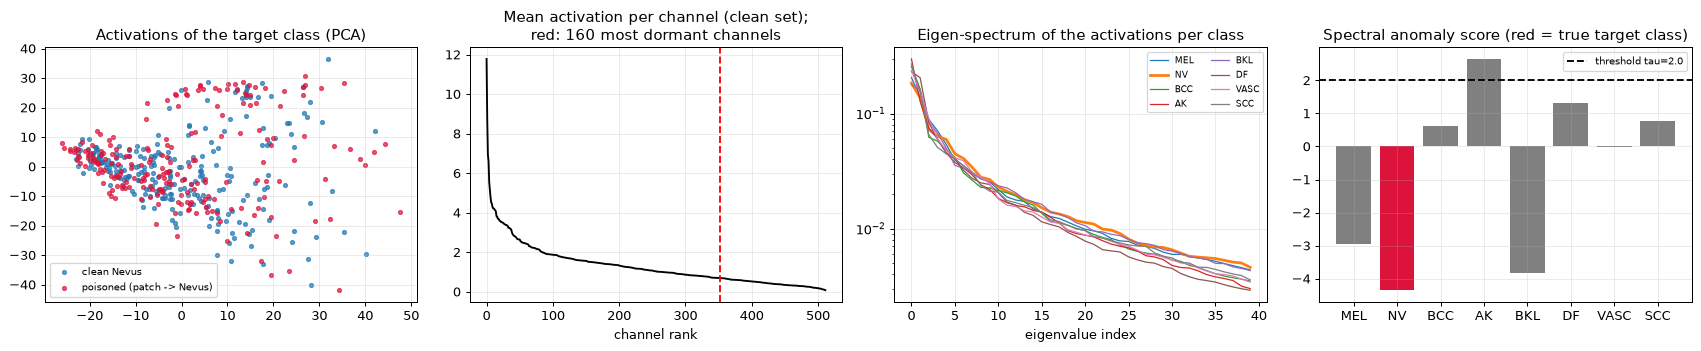

metrics per class (entropy, variance, dominant-eigenvalue ratio):
             MEL      NV     BCC      AK     BKL      DF    VASC     SCC
entropy    0.702   0.720   0.659   0.642   0.707   0.632   0.658   0.663
variance  33.439  29.060  45.445  52.062  31.616  49.134  42.606  46.033
dominant   0.182   0.162   0.233   0.273   0.157   0.213   0.216   0.243


In [17]:
# Paper Figs. 7-10: activations of the poisoned / unpoisoned data, dormant channels, eigen-spectra, anomaly scores (non-IID, trigger attack)
sc = scenario("noniid", "trigger", SEED)
Xp, yp, pp = sc["pool_X"], sc["pool_y"], sc["pool_p"]
fig, ax = plt.subplots(1, 4, figsize=(19, 4))

# Fig. 7: PCA of the activations of the target class: clean samples vs poisoned copies
ii = np.where(yp == TARGET_TRIGGER)[0]
Z = PCA(2, random_state=SEED).fit_transform(Xp[ii])
ax[0].scatter(Z[~pp[ii], 0], Z[~pp[ii], 1], s=10, label="clean Nevus", alpha=0.7)
ax[0].scatter(Z[pp[ii], 0], Z[pp[ii], 1], s=10, label="poisoned (patch -> Nevus)", alpha=0.7, color="crimson")
ax[0].set_title("Activations of the target class (PCA)"); ax[0].legend(fontsize=8)

# Fig. 8: dormant channels = lowest mean activation on the clean defence set
a = F_clean[def_idx].mean(0); order = np.argsort(a)
ax[1].plot(np.sort(a)[::-1], color="k"); ax[1].axvline(512 - 160, color="red", ls="--")
ax[1].set_title("Mean activation per channel (clean set);\nred: 160 most dormant channels"); ax[1].set_xlabel("channel rank")

# Fig. 10: normalised eigen-spectra per class (log scale)
spec = class_spectra(Xp, yp)
for c in range(NCLS):
    ev = spec[c]["ev"][:40]; ax[2].semilogy(ev / ev.sum() + 1e-12, label=SHORT[c], lw=2.2 if c == TARGET_TRIGGER else 1)
ax[2].set_title("Eigen-spectrum of the activations per class"); ax[2].set_xlabel("eigenvalue index"); ax[2].legend(fontsize=7, ncol=2)

# Fig. 9: the three spectral metrics and the combined anomaly score
sc_ = spectral_scores(spec)
ax[3].bar(np.arange(NCLS), sc_, color=["crimson" if c == TARGET_TRIGGER else "grey" for c in range(NCLS)])
ax[3].axhline(SPEC_TAU, color="k", ls="--", label=f"threshold tau={SPEC_TAU}")
ax[3].set_xticks(range(NCLS)); ax[3].set_xticklabels(SHORT); ax[3].set_title("Spectral anomaly score (red = true target class)"); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("metrics per class (entropy, variance, dominant-eigenvalue ratio):")
print(pd.DataFrame({SHORT[c]: [spec[c]["entropy"], spec[c]["var"], spec[c]["dom"]] for c in range(NCLS)}, index=["entropy", "variance", "dominant"]).round(3).to_string())

## 7. Side-by-side comparison with the paper

Verdict rule: a table entry is **reproduced** when it is within 2 percentage points of the paper, otherwise **not reached** (ours is lower) or **exceeded** (ours is higher) with the gap. Rows tagged *(direction)* test only the qualitative statement of the paper. **Cannot be checked** means the notebook has no way to measure the claim.

Two reading notes before the numbers. (1) The paper's "defence effectiveness" is not defined; the eight rows of each table satisfy *effectiveness = post-defence clean accuracy - post-defence BAR* to within about 0.4 points (for example 87.44 - 11.50 = 75.94), so that is what the code reproduces under the name `DE_paper_def`. It mixes accuracy and attack rate and is **not** the reduction of the BAR; `BAR_reduction` is printed next to it. (2) The paper's own numbers say that the *clean* accuracy before the defence is 37-55 % and 52-87 % afterwards, i.e. a defence is credited with raising clean accuracy by up to 40 points; the control row "plain fine-tune" tests whether that is a defence effect.

In [18]:
# ------------------------- Paper's Tables 1 and 2 (percent) and this notebook's re-measurement -------------------------
# columns: clean accuracy, BAR, post-defence clean accuracy, post-defence BAR, "defence effectiveness"
PAPER = {
    ("iid", "trigger"):   {"Spectral Defense": (47.01, 20.17, 77.14, 12.74, 64.71), "Activation Clustering": (37.01, 31.50, 67.40, 17.54, 49.70),
                           "Neural Cleanse": (50.01, 30.97, 61.60, 15.50, 45.71), "Fine-Pruning": (46.01, 25.97, 52.24, 25.53, 26.71)},
    ("iid", "semantic"):  {"Spectral Defense": (45.50, 28.75, 72.36, 15.14, 57.12), "Activation Clustering": (39.45, 29.83, 65.12, 20.36, 44.76),
                           "Neural Cleanse": (48.75, 23.45, 59.86, 18.40, 41.62), "Fine-Pruning": (44.50, 22.50, 50.36, 17.41, 33.12)},
    ("noniid", "trigger"): {"Spectral Defense": (47.01, 40.27, 87.44, 11.50, 75.94), "Activation Clustering": (45.01, 41.70, 67.24, 17.12, 50.12),
                            "Neural Cleanse": (40.01, 50.90, 61.14, 25.63, 35.71), "Fine-Pruning": (51.01, 40.54, 52.24, 35.53, 16.71)},
    ("noniid", "semantic"): {"Spectral Defense": (55.50, 11.75, 72.36, 10.24, 62.12), "Activation Clustering": (49.45, 19.83, 65.12, 15.36, 49.76),
                             "Neural Cleanse": (48.75, 23.45, 59.86, 19.56, 40.30), "Fine-Pruning": (44.50, 22.75, 50.36, 17.11, 33.25)},
}
TOL = 2.0     # percentage points: "reproduced" when |paper - notebook| <= 2

def verdict(paper, ours, tol=TOL):
    if np.isnan(ours): return "cannot be checked"
    if abs(paper - ours) <= tol: return "reproduced"
    return "exceeded by %.1f" % (ours - paper) if ours > paper else "not reached (%.1f below)" % (paper - ours)

cols = ["clean acc", "BAR", "PD clean acc", "PD-BAR", "defence eff."]
rows = []
for (split, attack), tab in PAPER.items():
    for name, vals in tab.items():
        r = dfD[(dfD.split == split) & (dfD.attack == attack) & (dfD.defence == name)]
        if r.empty: continue
        r = r.iloc[0]
        ours = (100 * r.clean_acc, 100 * r.BAR, 100 * r.PD_clean_acc, 100 * r.PD_BAR, 100 * r.DE_paper_def)
        for c, p, o in zip(cols, vals, ours):
            rows.append(dict(split=split, attack=attack, defence=name, metric=c, paper=p, notebook=round(o, 1), verdict=verdict(p, o)))
cmp_tab = pd.DataFrame(rows)
wide = cmp_tab.pivot_table(index=["split", "attack", "defence"], columns="metric", values=["paper", "notebook"], sort=False)
wide = wide.reindex(columns=pd.MultiIndex.from_product([["paper", "notebook"], cols]))
print("Tables 1-2, paper vs this notebook (percent):")
print(wide.round(1).to_string())
vc = cmp_tab.verdict.str.extract(r"^(reproduced|exceeded|not reached|cannot be checked)")[0].value_counts()
print("\nverdicts over the", len(cmp_tab), "table entries (tolerance 2 points):", vc.to_dict())

# ------------------------------------------ claim-level verdicts ------------------------------------------
claims = []
def add(claim, paper, ours, verdict_):
    claims.append(dict(claim=claim, paper=paper, notebook=ours, verdict=verdict_))

sb = summ.loc["noniid"]
for m, nm in (("acc", "accuracy"), ("prec", "precision"), ("rec", "recall"), ("f1", "F1")):
    d = sb.loc["hybrid", m] - sb.loc["linear", m]
    add(f"C1 hybrid vs classical ResNet-18 head: {nm} (non-IID, FedAvg)", "hybrid higher (no numbers)",
        f"hybrid {sb.loc['hybrid', m]:.3f} vs linear {sb.loc['linear', m]:.3f} (bottleneck {sb.loc['bottleneck', m]:.3f})",
        "reproduced (direction)" if d > 0.0 else f"not reached (hybrid {d:+.3f})")
d = sb.loc["hybrid", "secs"] / sb.loc["linear", "secs"]
add("C1 training-time advantage of the hybrid model", "hybrid faster (no numbers)", f"hybrid {sb.loc['hybrid','secs']:.0f}s vs linear {sb.loc['linear','secs']:.0f}s (simulated qubits)",
    "reproduced (direction)" if d < 1 else f"not reached ({d:.0f}x slower; the circuit is simulated)")

bt = dfA[(dfA.attack == "trigger") & (dfA.algo == "fedavg")].set_index("split").BAR
bs = dfA[(dfA.attack == "semantic") & (dfA.algo == "fedavg")].set_index("split").BAR
bt_c = dfCtrl[dfCtrl.algo == "fedavg"].set_index("split").base_rate_trigger
add("C2 trigger backdoor works (BAR well above the clean-federation base rate), non-IID",
    "BAR 40.27 % (Spectral row)", f"BAR {100*bt['noniid']:.1f} % vs base rate {100*bt_c['noniid']:.1f} %",
    "reproduced (direction)" if bt["noniid"] > bt_c["noniid"] + 0.10 else "not reached (attack too weak here)")
add("C2 non-IID makes the trigger backdoor stronger than IID", "20.17 % IID -> 40.27 % non-IID",
    f"{100*bt['iid']:.1f} % IID -> {100*bt['noniid']:.1f} % non-IID", "reproduced (direction)" if bt["noniid"] > bt["iid"] else "not reached (direction reversed or equal)")
add("C2 semantic backdoor, BAR", "28.75 % IID / 11.75 % non-IID", f"{100*bs['iid']:.1f} % IID / {100*bs['noniid']:.1f} % non-IID",
    verdict(11.75, 100 * bs["noniid"]) + " (non-IID value)")

nn = dfA[(dfA.split == "noniid") & (dfA.attack != "none")]
if nn.algo.nunique() > 1:
    g = nn.groupby("algo").agg(acc=("acc", "mean"), BAR=("BAR", "mean"))
    robust = g.loc[["scaffold", "fednova"]].mean(); plain = g.loc[["fedavg", "fedprox"]].mean()
    add("C3 SCAFFOLD / FedNova more resilient than FedAvg / FedProx (non-IID, both attacks)", "SCAFFOLD, FedNova more resilient (no numbers)",
        f"mean BAR {100*robust.BAR:.1f} % vs {100*plain.BAR:.1f} %; mean accuracy {100*robust.acc:.1f} % vs {100*plain.acc:.1f} %",
        ("reproduced (direction; one seed, noisy)" if robust.BAR < plain.BAR else "not reached (BAR not lower)"))

main = dfD[dfD.defence.isin(["Spectral Defense", "Activation Clustering", "Neural Cleanse", "Fine-Pruning"])]
wins, tot = 0, 0
for (sp, at), g in main.groupby(["split", "attack"]):
    tot += 1; wins += int(g.loc[g.DE_paper_def.idxmax(), "defence"] == "Spectral Defense")
add("C4 Spectral Defense has the best 'defence effectiveness' (PD acc - PD-BAR) among the four", "best in 4 of 4 settings", f"best in {wins} of {tot} settings",
    "reproduced" if wins == tot else f"not reached ({wins}/{tot})")
sp_ = main[main.defence == "Spectral Defense"]
add("C4 Spectral Defense lowers the BAR (PD-BAR < BAR)", "yes, all 4 settings", f"{int((sp_.PD_BAR < sp_.BAR).sum())} of {len(sp_)} settings",
    "reproduced" if (sp_.PD_BAR < sp_.BAR).all() else "not reached")
red = main.groupby("defence").BAR_reduction.mean() * 100
add("C4 BAR reduction by defence (mean over settings, points)", "Spectral largest", ", ".join(f"{k} {v:.1f}" for k, v in red.items()),
    "reproduced (direction)" if red.idxmax() == "Spectral Defense" else f"not reached (largest: {red.idxmax()})")

def de(split, name): return main[(main.split == split) & (main.defence == name)].DE_paper_def.mean() * 100
drops = {n: de("noniid", n) - de("iid", n) for n in ("Spectral Defense", "Neural Cleanse", "Fine-Pruning")}
add("C5 NC and FP lose effectiveness in non-IID, Spectral does not (change of DE, IID -> non-IID, points)",
    "Spectral +8.1 / NC -5.7 / FP -4.9 (mean of the two attacks)", ", ".join(f"{k} {v:+.1f}" for k, v in drops.items()),
    "reproduced" if (drops["Spectral Defense"] >= -2 and drops["Neural Cleanse"] < 0 and drops["Fine-Pruning"] < 0)
    else "partly (all three lose effectiveness, Spectral loses least)" if drops["Spectral Defense"] > max(drops["Neural Cleanse"], drops["Fine-Pruning"])
    else "not reached")
noc = dfD[dfD.defence == "Spectral (no clean data)"]; cl = dfD[dfD.defence == "Spectral Defense"]
add("C6 Spectral Defense works without clean validation data", "yes (Abstract)",
    f"PD-BAR {100*noc.PD_BAR.mean():.1f} % / PD acc {100*noc.PD_clean_acc.mean():.1f} % without clean data vs {100*cl.PD_BAR.mean():.1f} % / {100*cl.PD_clean_acc.mean():.1f} % with",
    "reproduced" if noc.PD_BAR.mean() <= noc.BAR.mean() - 0.05 and noc.PD_clean_acc.mean() >= noc.clean_acc.mean() - 0.03 else "not reached (BAR not clearly reduced or accuracy lost)")
ct = dfD[dfD.defence.str.startswith("Control")]
add("C7 gain in clean accuracy after repair is due to the defence", "47 % -> 77 % / 87 % (Tables 1-2)",
    f"plain fine-tune control {100*ct.PD_clean_acc.mean():.1f} % vs Spectral {100*cl.PD_clean_acc.mean():.1f} % (before: {100*cl.clean_acc.mean():.1f} %)",
    "cannot be attributed to the defence" if cl.PD_clean_acc.mean() - ct.PD_clean_acc.mean() < 0.02 else "defence adds accuracy beyond plain fine-tuning")
add("C8 dataset: 2,357 images, 9 classes", "ISIC 2,357 images, 9 classes", f"{N} images, 8 classes (ISIC 2019 mirror)", "cannot be checked exactly (substitute data)")
claims_df = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 140, "display.width", 250)
print("\nClaim-level verdicts:")
print(claims_df.to_string(index=False))

Tables 1-2, paper vs this notebook (percent):


                                          paper                                         notebook                                       
                                      clean acc   BAR PD clean acc PD-BAR defence eff. clean acc   BAR PD clean acc PD-BAR defence eff.
split  attack   defence                                                                                                                
iid    trigger  Spectral Defense           47.0  20.2         77.1   12.7         64.7      30.7  26.0         32.2   31.2          1.0
                Activation Clustering      37.0  31.5         67.4   17.5         49.7      30.7  26.0         32.0   20.9         11.1
                Neural Cleanse             50.0  31.0         61.6   15.5         45.7      30.7  26.0         31.6   23.8          7.7
                Fine-Pruning               46.0  26.0         52.2   25.5         26.7      30.7  26.0         27.8   30.0         -2.2
       semantic Spectral Defense           45.5

In [19]:
# ------------------------------- plain-language summary, computed from the verdicts above -------------------------------
v = claims_df.verdict
n_rep = int(v.str.startswith("reproduced").sum()); n_part = int(v.str.startswith("partly").sum())
n_not = int(v.str.startswith("not reached").sum()); n_exc = int(v.str.startswith("exceeded").sum()); n_cnc = int(v.str.startswith("cannot").sum())
print(f"Claim-level verdicts: {n_rep} reproduced (incl. direction-only), {n_part} partly, {n_not} not reached, {n_exc} exceeded, {n_cnc} cannot be checked.")
tab = cmp_tab.verdict.str.extract(r"^(reproduced|exceeded|not reached|cannot be checked)")[0].value_counts().to_dict()
print("Table entries (Tables 1-2, 80 numbers): ", tab, "- the absolute values are not comparable (different data, frozen backbone, 8 classes, much lower clean accuracy).")
print("\nWhat the runs support:")
print(f" - the trigger backdoor is learnable and stronger under non-IID data: BAR {100*bt['iid']:.0f} % (IID) -> {100*bt['noniid']:.0f} % (non-IID) vs base rate {100*bt_c['noniid']:.0f} %;")
print(f" - the hybrid head is NOT better than classical heads on the same features: accuracy {sb.loc['hybrid','acc']:.3f} vs {sb.loc['bottleneck','acc']:.3f} (classical twin) and {sb.loc['linear','acc']:.3f} (linear);")
print(f" - plain fine-tuning (control) gives {100*ct.PD_clean_acc.mean():.1f} % clean accuracy and {100*ct.BAR_reduction.mean():.1f} points of BAR reduction, against {100*cl.PD_clean_acc.mean():.1f} % and {100*cl.BAR_reduction.mean():.1f} points for the Spectral Defense: the paper's repair gains are not specific to the defence here.")

Claim-level verdicts: 3 reproduced (incl. direction-only), 1 partly, 9 not reached, 1 exceeded, 2 cannot be checked.
Table entries (Tables 1-2, 80 numbers):  {'not reached': 52, 'exceeded': 27, 'reproduced': 1} - the absolute values are not comparable (different data, frozen backbone, 8 classes, much lower clean accuracy).

What the runs support:
 - the trigger backdoor is learnable and stronger under non-IID data: BAR 26 % (IID) -> 44 % (non-IID) vs base rate 27 %;
 - the hybrid head is NOT better than classical heads on the same features: accuracy 0.321 vs 0.366 (classical twin) and 0.444 (linear);
 - plain fine-tuning (control) gives 33.5 % clean accuracy and 6.0 points of BAR reduction, against 33.8 % and 6.3 points for the Spectral Defense: the paper's repair gains are not specific to the defence here.


## Reading the paper critically

These points concern the *evidence*, not the sincerity of the work. It is a short, non-peer-reviewed preprint without code, seeds or confidence intervals.

1. **"Defence effectiveness" is not an effectiveness measure.** In all 16 table rows the number equals *post-defence clean accuracy minus post-defence BAR* (87.44 - 11.50 = 75.94; 52.24 - 25.53 = 26.71; the other rows agree to within 0.4). A defence that raises accuracy by 40 points and does not touch the BAR would score the same as one that halves the BAR. The standard quantity, the BAR reduction, gives a very different ranking (see the `BAR_reduction` column).
2. **The "repair" raises clean accuracy by 15 to 40 points.** Clean accuracy before the defence is 37-55 %, after it 50-87 %. Whatever the defence does, it ends with five epochs of fine-tuning on additional data, and the paper itself reports validation accuracy climbing from 57 % to 89 % over those five epochs. An under-trained starting model improves with *any* extra training. There is no control (plain fine-tuning) in the paper; the row "Control: plain fine-tune" in Experiment B is that control.
3. **Several numbers are identical across the IID and the non-IID table**, which independent runs would hardly produce: the post-defence clean accuracies 72.36 % (Spectral, semantic), 65.12 % (Activation Clustering, semantic), 59.86 % (Neural Cleanse, semantic), 50.36 % (Fine-Pruning, semantic) and 52.24 % (Fine-Pruning, trigger), and the pre-defence rows 48.75 % / 23.45 % (Neural Cleanse, semantic) appear in both tables.
4. **The analysis text belongs to a ten-class problem.** Section 7 names "suspected" classes 0, 1, 2, 4, 5, 6, 8 and 9 and a second list 0, 1, 2, 3, 6, 7, 9 for a 9-class (here 8-class) skin dataset; class 9 cannot exist and the two lists disagree. The eigen-spectrum analysis seems to come from another task (the notation, `model.conv1` and ten classes suggest a MNIST/CIFAR-style run).
5. **"Without recourse to clean validation data"** (Abstract) conflicts with Algorithm 1, which fine-tunes on labelled data `D` for several epochs. Experiment B tests both versions.
6. **Quantum advantage is asserted, not measured.** The Conclusion says the quantum-hybrid beats the classical ResNet-18 "in accuracy, precision, recall, F1 and training-time efficiency", but no numbers, seeds or baseline details are given, and the quantum layer is *simulated* on a GPU workstation, so a training-time advantage is impossible by construction. The "amplitude encoding" named in Section 2.2 is actually angle (RY) encoding.
7. **A cheap, honest comparison needs a base rate.** A trigger "works" only if the BAR exceeds what a clean model does with the same input. Here the clean federation sends a noticeable share of patched or re-lit images to the target class anyway (control table), which the paper does not report.
8. **Limits of this reproduction.** The ResNet-18 is frozen (the backdoor can only live in the head), images are 64 x 64, the data are the ISIC 2019 mirror with 8 classes instead of the paper's 9, the hybrid head is trained on a few thousand images and one seed for the defence tables, and the defences are our own implementations with thresholds chosen *before* looking at test BAR. The comparison with the paper's absolute numbers is therefore indicative; the qualitative claims (ordering of defences, effect of non-IID data, quantum vs classical) are the part that is genuinely tested.

## Exercises

1. **Stronger attacker.** Set `N_MALICIOUS = 3` or multiply the malicious client's update by a boost factor (add one line in `run_fl`) and re-run Experiment A. Which aggregation rule degrades first? Does the BAR still exceed the control base rate?
2. **How non-IID is non-IID?** Change `DIRICHLET_ALPHA` to 0.1, 0.5 and 5.0 and plot the BAR of the trigger attack against the printed mean Jensen-Shannon divergence. Is the paper's "non-IID helps the attacker" a smooth trend?
3. **Is the qubit layer doing anything?** Replace the circuit by the *bottleneck* head and the *linear* head (already available) and add a 4-qubit and an 8-qubit version (`N_QUBITS`). Where does accuracy peak? Does the BAR depend on the head?
4. **Fix the weak spot of the defence comparison.** The paper reports one number per cell. Re-run Experiment B with five seeds (`SEEDS = [42, ..., 46]`, loop over `run_defences`) and report mean +/- standard deviation. Which of the paper's rankings survive?
5. **Make the backbone trainable.** Unfreeze the last ResNet stage (`layer4`) in the head and let the backdoor live there as well. Do Fine-Pruning (which was designed for convolutional channels) and Neural Cleanse work better? What does it cost on a CPU?